# PREP_01 — Feature Engineering Indikator Teknikal (X1) — v4
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45

| | |
|---|---|
| **Mahasiswa** | Ilda Nurida (NRP 6032251068) |
| **Program Studi** | Magister Manajemen Teknologi - SIMT ITS |
| **Pembimbing** | Dr. Ir. Ahmad Saikhu, S.Si, MT. |
| **Periode Data** | Januari 2022 - Juni 2026 |
| **Tahun** | 2026 |

---

## Fitur Final

**Kolom referensi (bukan input model, untuk EDA/plot Bab 4):**
`Open, High, Low, Close, Volume, MA5, MA10, MA20, Volatilitas`

**X1 - Fitur Teknikal (15 kolom, INPUT MODEL):**
`Log_Return, Vol_Lag1, Vol_Lag2, Vol_Lag3, Vol_MA5, Vol_STD5,
MA5_Ratio, MA10_Ratio, MA20_Ratio, RSI14, Stoch_K, Stoch_D, Volume_ZScore,
R_Exit, GARCH_Forecast`  ← **[v4] 2 fitur hybrid GARCH (revisi reviewer)**

**[v4] Revisi lag:** lag kini relatif terhadap target $\sigma_{t+1}$ → `Vol_Lag1` $=\sigma_t$, `Vol_Lag2` $=\sigma_{t-1}$, `Vol_Lag3` $=\sigma_{t-2}$ (seluruhnya diketahui pada penutupan hari $t$).

**Y - Target (1 kolom):** `Volatilitas_Target` (= volatilitas `t+1`)

Buffer dua sisi digunakan agar tidak ada baris periode penelitian yang hilang: buffer pra-periode (Okt-Des 2021) menyerap warm-up rolling indikator, dan buffer pasca-periode (Jul 2026) menyediakan nilai `t+1` bagi hari perdagangan terakhir.


---
## ⚙️ CELL 1 — Import Library dan Konfigurasi Path

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
import os
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.family' : 'Times New Roman',
    'font.size'   : 10,
    'figure.dpi'  : 150,
})

# ═══════════════════════════════════════════════════════════
# PATH — DETEKSI OTOMATIS
# ═══════════════════════════════════════════════════════════
from pathlib import Path

NOTEBOOK_DIR = Path(os.getcwd())
ROOT = NOTEBOOK_DIR
for _ in range(5):
    if (ROOT / '03_dataset').exists():
        break
    ROOT = ROOT.parent

# ── Path Input
PATH_VOLATILITAS = ROOT / '03_dataset' / 'processed' / 'volatilitas.csv'
PATH_HARGA_RAW   = ROOT / '03_dataset' / 'raw'       / 'harga_saham_raw.csv'

# ── Path Output
DIR_PROCESSED    = ROOT / '03_dataset'     / 'processed'
DIR_TABEL        = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR       = ROOT / '06_dokumen_tesis' / 'gambar' / 'EDA'

for d in [DIR_PROCESSED, DIR_TABEL, DIR_GAMBAR]:
    d.mkdir(parents=True, exist_ok=True)

# ── Konfigurasi penelitian
URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']

NAMA_PERUSAHAAN = {
    'ADRO': 'Adaro Energy Indonesia Tbk',
    'ADMR': 'Adaro Minerals Indonesia Tbk',
    'ITMG': 'Indo Tambangraya Megah Tbk',
    'PTBA': 'Bukit Asam Tbk',
    'MEDC': 'Medco Energi Internasional Tbk',
    'AKRA': 'AKR Corporindo Tbk',
    'PGAS': 'Perusahaan Gas Negara Tbk',
}

WARNA_EMITEN = {
    'ADRO':'#1f77b4','ADMR':'#2ca02c','ITMG':'#ff7f0e',
    'PTBA':'#d62728','MEDC':'#9467bd','AKRA':'#8c564b','PGAS':'#e377c2',
}

# Tambahkan ke konfigurasi Cell 1
KOLOM_EMITEN_KANDIDAT = [
    'Emiten', 'Kode_Emiten', 'kode_emiten',
    'Ticker', 'Symbol', 'EMITEN', 'CODE'
]

print('=' * 65)
print('  ✅ Library dan konfigurasi berhasil dimuat')
print('=' * 65)
print(f'  ROOT project      : {ROOT}')
print(f'  Input volatilitas : {PATH_VOLATILITAS}')
print(f'  Input harga raw   : {PATH_HARGA_RAW}')
print(f'  Output processed  : {DIR_PROCESSED}')
print(f'  Output tabel      : {DIR_TABEL}')
print(f'  Output gambar     : {DIR_GAMBAR}')
print()
print(f'  Emiten penelitian : {URUTAN_EMITEN}')

  ✅ Library dan konfigurasi berhasil dimuat
  ROOT project      : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
  Input volatilitas : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\volatilitas.csv
  Input harga raw   : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw\harga_saham_raw.csv
  Output processed  : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed
  Output tabel      : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\tabel
  Output gambar     : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PRE

In [2]:
from pathlib import Path
import pandas as pd

EKSTENSI = {'.csv', '.json', '.pkl', '.keras', '.h5', '.joblib', '.py', '.ipynb'}
FOLDER_DILEWATI = {'.venv', 'venv', 'env', 'site-packages', '.git', '__pycache__',
                   '.ipynb_checkpoints', 'node_modules', '.vscode'}

baris_output = []
for p in sorted(Path(ROOT).rglob('*')):
    # Lewati file di dalam folder library / sistem
    if any(bagian in FOLDER_DILEWATI for bagian in p.parts):
        continue
    if p.suffix.lower() not in EKSTENSI:
        continue

    ukuran_kb = p.stat().st_size / 1024
    info = ''
    if p.suffix.lower() == '.csv':
        try:
            df = pd.read_csv(p, nrows=3, encoding='utf-8-sig')
            info = f'| kolom: {list(df.columns)}'
        except pd.errors.EmptyDataError:
            info = '| ⚠️ FILE KOSONG'
        except Exception as e:
            info = f'| ⚠️ GAGAL DIBACA: {type(e).__name__}'

    baris_output.append(f'{p.relative_to(ROOT)} ({ukuran_kb:,.1f} KB) {info}')

path_daftar = Path(ROOT) / 'daftar_file_tesis.txt'
path_daftar.write_text('\n'.join(baris_output), encoding='utf-8')
print(f'✅ {len(baris_output)} file tercatat (tanpa folder library).')
print(f'Daftar lengkap disimpan di:\n{path_daftar}')

✅ 409 file tercatat (tanpa folder library).
Daftar lengkap disimpan di:
e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\daftar_file_tesis.txt


---
## CELL 1B [BARU v3] - Re-scraping Data Harga dengan Buffer Dua Sisi

**Sel ini adalah inti perbaikan v3.** Jalankan **satu kali** untuk memperbarui
`harga_saham_raw.csv`, lalu jalankan CELL 2 dan seterusnya seperti biasa.
Jika file buffer sudah pernah dibuat, sel ini otomatis melewati proses unduh.

### Mengapa buffer diperlukan

| Sisi | Rentang | Fungsi |
|---|---|---|
| **Pra-periode** | Okt - Des 2021 | Menyerap warm-up rolling. Fitur pengikat adalah `Vol_MA5` (butuh 24 observasi: 20 untuk volatilitas + 5 untuk rata-rata bergerak, dikurangi 1 karena tumpang tindih). |
| **Pasca-periode** | Jul 2026 | Menyediakan nilai $t+1$ bagi `Volatilitas_Target` pada hari perdagangan terakhir (30 Juni 2026). |

Tanpa buffer pra-periode, 23 hari perdagangan pertama (3 Januari - 4 Februari 2022)
terbuang. Tanpa buffer pasca-periode, hari perdagangan terakhir selalu hilang.

### Catatan teknis

- `auto_adjust=False` **wajib**, agar kolom `Adj_Close` tetap tersedia. CELL 3
  membutuhkannya untuk menghitung faktor koreksi `Adj_Close / Close` yang
  menskalakan Open/High/Low ke basis yang sama dengan Close - tanpa ini,
  Stochastic Oscillator akan keluar dari rentang 0-100.
- Buffer 60 hari kalender pra-periode setara sekitar 40 hari bursa, cukup lapang
  terhadap kebutuhan 24 observasi.


In [3]:
print('=' * 70)
print('  CELL 1B [v3] - RE-SCRAPING DATA HARGA DENGAN BUFFER DUA SISI')
print('=' * 70)

import pandas as pd

# ---- Konfigurasi buffer
BUFFER_AWAL   = '2021-10-01'   # ~60 hari kalender sebelum periode penelitian
BUFFER_AKHIR  = '2026-07-16'   # > 30 Jun 2026, agar target t+1 hari terakhir ada
PERIODE_AWAL_ = '2022-01-01'
PERIODE_AKHIR_= '2026-06-30'

PATH_RAW = ROOT / '03_dataset' / 'raw' / 'harga_saham_raw.csv'
PATH_RAW.parent.mkdir(parents=True, exist_ok=True)

# ---- Cek apakah file yang ada sudah memuat buffer
PERLU_UNDUH = True
if PATH_RAW.exists():
    _cek = pd.read_csv(PATH_RAW, usecols=['Date'], encoding='utf-8-sig')
    _cek['Date'] = pd.to_datetime(_cek['Date'])
    _min, _max = _cek['Date'].min(), _cek['Date'].max()
    print(f'  File lama ditemukan : {_min:%d/%m/%Y} - {_max:%d/%m/%Y} ({len(_cek):,} baris)')
    if _min <= pd.Timestamp('2021-12-01') and _max >= pd.Timestamp('2026-07-01'):
        PERLU_UNDUH = False
        print('  [OK] Buffer dua sisi sudah memadai - unduh dilewati')
    else:
        print('  [!] Buffer belum memadai - akan diunduh ulang')
else:
    print('  File belum ada - akan diunduh')

# ---- Unduh
if PERLU_UNDUH:
    import yfinance as yf

    frames = []
    for kode in URUTAN_EMITEN:
        d = yf.download(f'{kode}.JK', start=BUFFER_AWAL, end=BUFFER_AKHIR,
                        auto_adjust=False, progress=False)   # False -> Adj_Close ikut
        if isinstance(d.columns, pd.MultiIndex):
            d.columns = d.columns.get_level_values(0)
        d = d.reset_index()
        d.columns = [str(c).replace(' ', '_') for c in d.columns]  # 'Adj Close' -> 'Adj_Close'
        if 'Adj_Close' not in d.columns:
            d['Adj_Close'] = d['Close']
        d['Emiten'] = kode
        frames.append(d[['Date', 'Open', 'High', 'Low', 'Close',
                         'Adj_Close', 'Volume', 'Emiten']])
        print(f'  [OK] {kode:<5}: {len(d):,} baris '
              f'({d["Date"].min():%d/%m/%Y} - {d["Date"].max():%d/%m/%Y})')

    df_unduh = (pd.concat(frames, ignore_index=True)
                  .sort_values(['Emiten', 'Date'])
                  .reset_index(drop=True))
    df_unduh.to_csv(PATH_RAW, index=False, encoding='utf-8-sig')

    n_pra  = (df_unduh['Date'] < PERIODE_AWAL_).sum()  // len(URUTAN_EMITEN)
    n_pasca= (df_unduh['Date'] > PERIODE_AKHIR_).sum() // len(URUTAN_EMITEN)

    print(f'\n  Tersimpan : {PATH_RAW.resolve()}')
    print(f'  Total     : {len(df_unduh):,} baris (termasuk buffer)')
    print(f'  Buffer pra-periode   : ~{n_pra} hari bursa/emiten (butuh >= 24)')
    print(f'  Buffer pasca-periode : ~{n_pasca} hari bursa/emiten (butuh >= 1)')

    assert n_pra >= 24, (
        f'[X] Buffer pra-periode hanya {n_pra} hari bursa, minimal 24. '
        f'Mundurkan BUFFER_AWAL.')
    assert n_pasca >= 1, (
        f'[X] Buffer pasca-periode kosong. Majukan BUFFER_AKHIR.')
    print('  [OK] Buffer dua sisi memadai')


  CELL 1B [v3] - RE-SCRAPING DATA HARGA DENGAN BUFFER DUA SISI
  File lama ditemukan : 01/10/2021 - 15/07/2026 (7,979 baris)
  [OK] Buffer dua sisi sudah memadai - unduh dilewati


---
## 📂 CELL 2 — Load Dataset

Load `harga_saham_raw.csv` (OHLCV lengkap, 7 emiten sektor energi LQ45, Jan 2022 – Jun 2026).

In [4]:
print('=' * 65)
print('  📂 CELL 2 — LOAD DAN STANDARISASI DATA HARGA SAHAM')
print('=' * 65)

from pathlib import Path

# ── Path file harga saham
# Prioritas: cari dari folder scraping dulu, lalu folder raw
KANDIDAT_PATH_HARGA = [
    ROOT / '03_dataset' / 'raw' / 'harga_saham_raw.csv',
    Path(r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
         r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026'
         r'\01_scraping_data\harga_saham\harga_saham_raw.csv'),
    Path(r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
         r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026'
         r'\03_dataset\raw\harga_saham_raw.csv'),
]

PATH_HARGA_LOAD = None
for p in KANDIDAT_PATH_HARGA:
    if p.exists():
        PATH_HARGA_LOAD = p
        break

if PATH_HARGA_LOAD is None:
    print('❌ File harga saham tidak ditemukan di semua lokasi:')
    for p in KANDIDAT_PATH_HARGA:
        print(f'   {p}')
    raise FileNotFoundError('harga_saham_raw.csv tidak ditemukan')

print(f'  ✅ File ditemukan: {PATH_HARGA_LOAD}')

# ── Load CSV
df_harga_raw = pd.read_csv(PATH_HARGA_LOAD, encoding='utf-8-sig')
print(f'  Shape awal   : {df_harga_raw.shape}')
print(f'  Kolom awal   : {list(df_harga_raw.columns)}')
print()

# ════════════════════════════════════════════════════════════
# DETEKSI DAN STANDARISASI FORMAT
# ════════════════════════════════════════════════════════════

KOLOM_EMITEN_KANDIDAT = [
    'Kode_Emiten', 'kode_emiten', 'KODE_EMITEN',
    'Emiten', 'emiten', 'EMITEN',
    'Ticker', 'ticker', 'TICKER',
    'Symbol', 'symbol', 'SYMBOL',
    'Code', 'code', 'CODE',
    'Kode Emiten', 'KODE EMITEN',
]

kolom          = [str(c) for c in df_harga_raw.columns]
ada_emiten_col = any(c in KOLOM_EMITEN_KANDIDAT for c in kolom)
ada_kode_col   = any(e in kolom for e in URUTAN_EMITEN)

# ════════════════════════════════════════════════════════════
# FORMAT LONG — ada kolom identitas emiten
# ════════════════════════════════════════════════════════════
if ada_emiten_col:
    print('  📋 Format terdeteksi: LONG')
    df_harga = df_harga_raw.copy()

    # ── Rename kolom emiten → 'Emiten'
    for c in df_harga.columns:
        if str(c) in KOLOM_EMITEN_KANDIDAT:
            if str(c) != 'Emiten':
                df_harga.rename(columns={c: 'Emiten'}, inplace=True)
                print(f'  ✅ Rename "{c}" → "Emiten"')
            break

    # ── Rename kolom tanggal → 'Date'
    for c in df_harga.columns:
        if str(c).lower() in ['tanggal','date','tgl','waktu','time']:
            if str(c) != 'Date':
                df_harga.rename(columns={c: 'Date'}, inplace=True)
                print(f'  ✅ Rename "{c}" → "Date"')
            break

    # ── Tentukan kolom harga: Adj_Close > Adj Close > Close
    if 'Adj_Close' in df_harga.columns:
        COL_HARGA = 'Adj_Close'
        print(f'  ✅ Kolom harga: Adj_Close')
    elif 'Adj Close' in df_harga.columns:
        df_harga.rename(columns={'Adj Close': 'Adj_Close'}, inplace=True)
        COL_HARGA = 'Adj_Close'
        print(f'  ✅ Kolom harga: "Adj Close" → "Adj_Close"')
    elif 'Close' in df_harga.columns:
        COL_HARGA = 'Close'
        print(f'  ✅ Kolom harga: Close')
    else:
        close_kandidat = [c for c in df_harga.columns
                          if 'close' in str(c).lower()]
        if close_kandidat:
            COL_HARGA = close_kandidat[0]
            print(f'  ✅ Kolom harga: {COL_HARGA}')
        else:
            raise ValueError(
                f'❌ Kolom harga tidak ditemukan!\n'
                f'   Kolom tersedia: {list(df_harga.columns)}'
            )

    # ── Rename OHLCV ke standar
    rename_ohlcv = {}
    for c in df_harga.columns:
        cl = str(c).lower()
        if cl == 'high'    and c != 'High'  : rename_ohlcv[c] = 'High'
        if cl == 'low'     and c != 'Low'   : rename_ohlcv[c] = 'Low'
        if cl == 'open'    and c != 'Open'  : rename_ohlcv[c] = 'Open'
        if cl == 'volume'  and c != 'Volume': rename_ohlcv[c] = 'Volume'
    if rename_ohlcv:
        df_harga.rename(columns=rename_ohlcv, inplace=True)
        print(f'  ✅ Rename OHLCV: {rename_ohlcv}')

# ════════════════════════════════════════════════════════════
# FORMAT WIDE — kolom = nama emiten langsung
# ════════════════════════════════════════════════════════════
elif ada_kode_col:
    print('  📋 Format terdeteksi: WIDE → konversi ke LONG')

    col_date = next(
        (c for c in kolom
         if str(c).lower() in ['date','tanggal','tgl','waktu']),
        kolom[0]
    )
    emiten_cols = [e for e in URUTAN_EMITEN if e in kolom]
    print(f'  Kolom tanggal    : {col_date}')
    print(f'  Emiten ditemukan : {emiten_cols}')

    df_harga = pd.melt(
        df_harga_raw,
        id_vars    = [col_date],
        value_vars = emiten_cols,
        var_name   = 'Emiten',
        value_name = 'Close',
    )
    df_harga.rename(columns={col_date: 'Date'}, inplace=True)
    COL_HARGA = 'Close'
    print(f'  ✅ Konversi WIDE → LONG selesai: {len(emiten_cols)} emiten')

# ════════════════════════════════════════════════════════════
# FORMAT TIDAK DIKENALI
# ════════════════════════════════════════════════════════════
else:
    print('  ❌ Format tidak dikenali!')
    print(f'  Kolom tersedia : {kolom}')
    raise ValueError('Format kolom tidak dikenali')

# ════════════════════════════════════════════════════════════
# STANDARISASI AKHIR
# ════════════════════════════════════════════════════════════

# ── Konversi Date
df_harga['Date'] = pd.to_datetime(df_harga['Date'], errors='coerce')
n_nat = df_harga['Date'].isna().sum()
if n_nat > 0:
    print(f'  ⚠️  {n_nat} baris tanggal tidak valid, dibuang')
df_harga.dropna(subset=['Date'], inplace=True)

# ── Konversi kolom harga ke numerik
df_harga[COL_HARGA] = pd.to_numeric(df_harga[COL_HARGA], errors='coerce')

# ── Urutkan kronologis per emiten
df_harga.sort_values(['Emiten', 'Date'], inplace=True)
df_harga.reset_index(drop=True, inplace=True)

# ── Simpan COL_HARGA untuk digunakan Cell 3
print(f'\n  📌 COL_HARGA untuk Cell 3 : "{COL_HARGA}"')

# ── Info final
print()
print('=' * 65)
print('  ✅ Data harga siap')
print(f'  Total baris  : {len(df_harga):,}')
print(f'  Kolom        : {list(df_harga.columns)}')
print(f'  Kolom harga  : {COL_HARGA}')
print(f'  Emiten       : {sorted(df_harga["Emiten"].unique().tolist())}')
print(f'  Periode      : {df_harga["Date"].min().date()} → '
      f'{df_harga["Date"].max().date()}')
print()
print('  Preview 5 baris:')
display(df_harga.head(5))

  📂 CELL 2 — LOAD DAN STANDARISASI DATA HARGA SAHAM
  ✅ File ditemukan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw\harga_saham_raw.csv
  Shape awal   : (7979, 8)
  Kolom awal   : ['Date', 'Open', 'High', 'Low', 'Close', 'Adj_Close', 'Volume', 'Emiten']

  📋 Format terdeteksi: LONG
  ✅ Kolom harga: Adj_Close

  📌 COL_HARGA untuk Cell 3 : "Adj_Close"

  ✅ Data harga siap
  Total baris  : 7,979
  Kolom        : ['Date', 'Open', 'High', 'Low', 'Close', 'Adj_Close', 'Volume', 'Emiten']
  Kolom harga  : Adj_Close
  Emiten       : ['ADMR', 'ADRO', 'AKRA', 'ITMG', 'MEDC', 'PGAS', 'PTBA']
  Periode      : 2021-10-01 → 2026-07-15

  Preview 5 baris:


,Date,Open,High,Low,Close,Adj_Close,Volume,Emiten
0,2022-01-03,135.0,135.0,135.0,135.0,125.224686,34289600,ADMR
1,2022-01-04,182.0,182.0,182.0,182.0,168.821442,22170900,ADMR
2,2022-01-05,220.0,244.0,220.0,244.0,226.332031,43203600,ADMR
3,2022-01-06,304.0,304.0,304.0,304.0,281.987457,52097500,ADMR
4,2022-01-07,380.0,380.0,380.0,380.0,352.484314,19248600,ADMR


---
## CELL 3 - Fitur Dasar: Log Return, Volatilitas (+Target h+1), MA/Rasio MA, Stochastic

**Log Return:**
$$R_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$

**Volatilitas (rolling 20 hari):**
$$\text{Vol}_t = \text{std}(R_{t-19}, ..., R_t)$$

**Target Y (forecast h+1):**
$$Y_t = \text{Vol}_{t+1}$$
Fitur hari $t$ tidak pernah menyertakan informasi yang membentuk Y pada hari yang sama.

**Fitur autoregresif volatilitas:**
$$\text{Vol\_Lag}k_t = \sigma_{t-k+1}, \quad k = 1,2,3 \quad (\text{lag ke-}k\text{ terhadap target } \sigma_{t+1})$$

**[v4] Return keluar window:** $\text{R\_Exit}_t = R_{t-19}$ (return yang keluar dari window 20 hari pada $t+1$).

**Rasio MA (stasioner, menggantikan level MA mentah sebagai fitur):**
$$\text{MA}_n\_\text{Ratio}_t = \frac{\text{Close}_t}{\text{MA}_{n,t}} - 1$$

**Stochastic Oscillator:**
$$\%K_t = \frac{\text{Close}_t - \text{Low}_{14}}{\text{High}_{14} - \text{Low}_{14}} \times 100, \quad \%D_t = \text{MA}_3(\%K_t)$$


In [5]:
print('=' * 70)
print('  CELL 3 - FITUR DASAR (Log Return, Volatilitas + Target, MA/Rasio, Stochastic)')
print('=' * 70)

dict_fitur = {}

# -- PILIH KOLOM HARGA
if 'Adj_Close' in df_harga.columns:
    COL_HARGA = 'Adj_Close'
elif 'Adj Close' in df_harga.columns:
    COL_HARGA = 'Adj Close'
else:
    COL_HARGA = 'Close'
print(f'Kolom harga digunakan : {COL_HARGA}')
print()

for emiten in URUTAN_EMITEN:

    df_e = df_harga[df_harga['Emiten'] == emiten].copy()
    if df_e.empty:
        print(f'  [X] {emiten}: data kosong')
        continue
    df_e = df_e.sort_values('Date').reset_index(drop=True)

    # -- PILIH KOLOM (+ Close mentah untuk faktor adjustment)
    kolom_pilih = {
        'Date': 'Date', 'Emiten': 'Emiten', 'Open': 'Open',
        COL_HARGA: 'Close', 'High': 'High', 'Low': 'Low', 'Volume': 'Volume'
    }
    if COL_HARGA != 'Close' and 'Close' in df_e.columns:
        kolom_pilih['Close'] = 'Close_Raw'        # simpan close mentah

    kolom_ada = {k: v for k, v in kolom_pilih.items() if k in df_e.columns}
    df_e = df_e[list(kolom_ada.keys())].copy()
    df_e.rename(columns=kolom_ada, inplace=True)
    df_e = df_e.loc[:, ~df_e.columns.duplicated()]

    # ==========================================================
    # FIX BASIS HARGA: skala Open/High/Low ke basis adjusted
    # dengan faktor = Adj_Close / Close_mentah, agar Stochastic
    # (berbasis rentang H-L) konsisten satu basis dengan Close.
    # ==========================================================
    if 'Close_Raw' in df_e.columns:
        faktor = df_e['Close'] / df_e['Close_Raw'].replace(0, np.nan)
        for c in ('Open', 'High', 'Low'):
            if c in df_e.columns:
                df_e[c] = df_e[c] * faktor
        df_e.drop(columns='Close_Raw', inplace=True)

    if 'Open' not in df_e.columns:   df_e['Open'] = df_e['Close']
    if 'High' not in df_e.columns:   df_e['High'] = df_e['Close']
    if 'Low' not in df_e.columns:    df_e['Low'] = df_e['Close']
    if 'Volume' not in df_e.columns: df_e['Volume'] = 0

    df_e.dropna(subset=['Close'], inplace=True)
    df_e.reset_index(drop=True, inplace=True)

    # -- 1. LOG RETURN
    df_e['Log_Return'] = np.log(df_e['Close'] / df_e['Close'].shift(1))

    # -- 2. VOLATILITAS + TARGET FORECAST (t+1)
    df_e['Volatilitas'] = df_e['Log_Return'].rolling(window=20, min_periods=20).std()
    df_e['Volatilitas_Target'] = df_e['Volatilitas'].shift(-1)

    # -- 3. FITUR AUTOREGRESIF VOLATILITAS
    #      sepenuhnya diketahui pada waktu t -> BUKAN leakage, dan merupakan
    #      prediktor terkuat (random walk benchmark).
    # [v4] REVISI: lag relatif terhadap TARGET sigma_{t+1}. Versi v3
    #      memakai shift(1..3) sehingga sigma_t (diketahui di t) tidak
    #      pernah dilihat model -> efektif forecast 2 hari ke depan.
    df_e['Vol_Lag1'] = df_e['Volatilitas']            # sigma_t
    df_e['Vol_Lag2'] = df_e['Volatilitas'].shift(1)   # sigma_{t-1}
    df_e['Vol_Lag3'] = df_e['Volatilitas'].shift(2)   # sigma_{t-2}
    # [v4] Return yang KELUAR dari window 20 hari pada t+1
    df_e['R_Exit']   = df_e['Log_Return'].shift(19)   # r_{t-19}
    # [v3] min_periods penuh - warm-up diserap buffer, bukan periode penelitian
    df_e['Vol_MA5']  = df_e['Volatilitas'].rolling(window=5, min_periods=5).mean()
    df_e['Vol_STD5'] = df_e['Volatilitas'].rolling(window=5, min_periods=5).std()

    # -- 4. MOVING AVERAGE (level utk plot) + RASIO (fitur model)
    # [v3] min_periods=n agar MA20 awal tidak berisi rata-rata parsial 1-19 hari
    df_e['MA5']  = df_e['Close'].rolling(5,  min_periods=5).mean()
    df_e['MA10'] = df_e['Close'].rolling(10, min_periods=10).mean()
    df_e['MA20'] = df_e['Close'].rolling(20, min_periods=20).mean()
    df_e['MA5_Ratio']  = df_e['Close'] / df_e['MA5'].replace(0, np.nan)  - 1
    df_e['MA10_Ratio'] = df_e['Close'] / df_e['MA10'].replace(0, np.nan) - 1
    df_e['MA20_Ratio'] = df_e['Close'] / df_e['MA20'].replace(0, np.nan) - 1

    # -- 5. STOCHASTIC (High/Low sudah satu basis dengan Close)
    low14  = df_e['Low'].rolling(14, min_periods=14).min()
    high14 = df_e['High'].rolling(14, min_periods=14).max()
    df_e['Stoch_K'] = (df_e['Close'] - low14) / (high14 - low14).replace(0, np.nan) * 100
    df_e['Stoch_D'] = df_e['Stoch_K'].rolling(3, min_periods=3).mean()

    # -- VALIDASI PER EMITEN
    sk_e = df_e['Stoch_K'].dropna()
    assert sk_e.between(-0.01, 100.01).all(), (
        f'[X] {emiten}: Stoch_K keluar 0-100 (min={sk_e.min():.1f}) - '
        f'basis harga masih campur, cek kolom Adj_Close/Close di data sumber')
    assert ((df_e['Low'] <= df_e['Close'] * 1.001) &
            (df_e['Close'] <= df_e['High'] * 1.001)).all(), (
        f'[X] {emiten}: Close di luar rentang Low-High setelah adjustment')

    # -- DIAGNOSTIK WARM-UP: baris valid pertama per fitur pengikat
    idx_lag3 = df_e['Vol_Lag3'].first_valid_index()
    idx_ma5v = df_e['Vol_MA5'].first_valid_index()
    idx_bind = max(idx_lag3 or 0, idx_ma5v or 0)

    dict_fitur[emiten] = df_e
    print(f'  [OK] {emiten:<5}: {len(df_e):,} baris | Stoch_K [{sk_e.min():.1f}, {sk_e.max():.1f}] '
          f'| warm-up berakhir idx {idx_bind} ({df_e["Date"].iloc[idx_bind]:%d/%m/%Y})')

print()
print(f'  SELESAI: {len(dict_fitur)}/{len(URUTAN_EMITEN)} emiten - basis OHLC adjusted konsisten')
print('  Catatan: tanggal "warm-up berakhir" di atas HARUS <= awal periode penelitian')
print('           (2022-01-03). Jika belum, perpanjang buffer di CELL 1B.')


  CELL 3 - FITUR DASAR (Log Return, Volatilitas + Target, MA/Rasio, Stochastic)
Kolom harga digunakan : Adj_Close

  [OK] ADRO : 1,149 baris | Stoch_K [0.0, 100.0] | warm-up berakhir idx 24 (05/11/2021)
  [OK] ADMR : 1,085 baris | Stoch_K [0.0, 100.0] | warm-up berakhir idx 24 (07/02/2022)
  [OK] ITMG : 1,149 baris | Stoch_K [0.0, 100.0] | warm-up berakhir idx 24 (05/11/2021)
  [OK] PTBA : 1,149 baris | Stoch_K [-0.0, 100.0] | warm-up berakhir idx 24 (05/11/2021)
  [OK] MEDC : 1,149 baris | Stoch_K [0.0, 100.0] | warm-up berakhir idx 24 (05/11/2021)
  [OK] AKRA : 1,149 baris | Stoch_K [0.0, 100.0] | warm-up berakhir idx 24 (05/11/2021)
  [OK] PGAS : 1,149 baris | Stoch_K [-0.0, 100.0] | warm-up berakhir idx 24 (05/11/2021)

  SELESAI: 7/7 emiten - basis OHLC adjusted konsisten
  Catatan: tanggal "warm-up berakhir" di atas HARUS <= awal periode penelitian
           (2022-01-03). Jika belum, perpanjang buffer di CELL 1B.


---
## 📊 CELL 4 — Perhitungan RSI (Relative Strength Index)

$$RSI = 100 - \frac{100}{1 + RS}, \quad RS = \frac{\text{Rata-rata Kenaikan (14 hari)}}{\text{Rata-rata Penurunan (14 hari)}}$$

- RSI > 70 → overbought (potensi koreksi turun)
- RSI < 30 → oversold (potensi rebound naik)

In [6]:
print('=' * 70)
print("  CELL 4 - RSI (14 hari, Wilder's Smoothing)")
print('=' * 70)

def hitung_rsi(series, window=14):
    """RSI dengan Wilder's Smoothing.

    [v3] Perbaikan edge case: pada v2, urutan .where() menyebabkan kondisi harga
    datar sempurna (avg_gain = avg_loss = 0, mis. saham tersuspensi) menghasilkan
    RSI = 0, padahal semestinya 50 (netral). Kini ketiga kondisi batas ditangani
    secara eksplisit dan saling eksklusif.
    """
    delta = series.diff()
    gain = delta.where(delta > 0, 0.0)
    loss = -delta.where(delta < 0, 0.0)

    avg_gain = gain.ewm(alpha=1/window, min_periods=window, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/window, min_periods=window, adjust=False).mean()

    rs  = avg_gain / avg_loss.replace(0, np.nan)
    rsi = 100 - (100 / (1 + rs))

    # -- Edge case eksplisit (urutan tidak lagi saling menimpa)
    naik_murni = (avg_loss == 0) & (avg_gain > 0)    # -> RSI 100
    turun_murni = (avg_gain == 0) & (avg_loss > 0)   # -> RSI 0
    datar = (avg_gain == 0) & (avg_loss == 0)        # -> RSI 50 (netral)

    rsi = rsi.mask(naik_murni, 100.0)
    rsi = rsi.mask(turun_murni, 0.0)
    rsi = rsi.mask(datar, 50.0)

    return rsi.clip(0, 100)


for emiten in URUTAN_EMITEN:
    if emiten not in dict_fitur:
        continue

    df_e = dict_fitur[emiten].copy()
    df_e['RSI14'] = hitung_rsi(df_e['Close'], window=14)
    dict_fitur[emiten] = df_e

    rsi_mean = df_e['RSI14'].mean()
    rsi_min  = df_e['RSI14'].min()
    rsi_max  = df_e['RSI14'].max()
    missing  = df_e['RSI14'].isna().sum()

    print(f'  [OK] {emiten:<6}: RSI14 | mean={rsi_mean:.2f}, min={rsi_min:.2f}, '
          f'max={rsi_max:.2f}, missing={missing}')

print()
print('  Perhitungan RSI selesai untuk semua emiten')


  CELL 4 - RSI (14 hari, Wilder's Smoothing)
  [OK] ADRO  : RSI14 | mean=53.42, min=23.68, max=88.77, missing=13
  [OK] ADMR  : RSI14 | mean=50.32, min=14.59, max=96.87, missing=13
  [OK] ITMG  : RSI14 | mean=52.16, min=20.64, max=91.35, missing=13
  [OK] PTBA  : RSI14 | mean=51.51, min=19.41, max=88.50, missing=13
  [OK] MEDC  : RSI14 | mean=51.23, min=21.74, max=88.88, missing=13
  [OK] AKRA  : RSI14 | mean=51.76, min=24.90, max=81.30, missing=13
  [OK] PGAS  : RSI14 | mean=51.50, min=16.41, max=83.79, missing=13

  Perhitungan RSI selesai untuk semua emiten


In [7]:
print('=' * 70)
print('  CELL 8 - TABEL MOMENTUM: RSI & STOCHASTIC OSCILLATOR')
print('=' * 70)

# Pastikan df_all tersedia (jika belum, gabungkan dari dict_fitur)
if 'df_all' not in globals():
    df_all = pd.concat([v.copy() for v in dict_fitur.values()], ignore_index=True)
    df_all = df_all.sort_values(['Emiten', 'Date']).reset_index(drop=True)

# Pastikan kolom Stoch_D ada untuk aggregasi
if 'Stoch_D' not in df_all.columns:
    df_all['Stoch_D'] = np.nan

tabel_4_6 = df_all.groupby('Emiten').agg(
    RSI_Mean=('RSI14',  'mean'), RSI_Std=('RSI14',  'std'),
    RSI_Min =('RSI14',  'min'),  RSI_Max=('RSI14',  'max'),
    K_Mean  =('Stoch_K','mean'), K_Std  =('Stoch_K','std'),
    D_Mean  =('Stoch_D','mean'), D_Std  =('Stoch_D','std'),
).reindex(URUTAN_EMITEN).round(2)

tabel_4_6.to_csv(DIR_TABEL / 'tabel_4_6_indikator_momentum.csv', encoding='utf-8-sig')
print(tabel_4_6.to_string())

  CELL 8 - TABEL MOMENTUM: RSI & STOCHASTIC OSCILLATOR
        RSI_Mean  RSI_Std  RSI_Min  RSI_Max  K_Mean  K_Std  D_Mean  D_Std
Emiten                                                                   
ADRO       53.42    11.65    23.68    88.77   52.03  29.05   52.02  26.88
ADMR       50.32    12.92    14.59    96.87   46.02  28.29   45.93  26.17
ITMG       52.16    11.34    20.64    91.35   50.72  30.92   50.69  28.81
PTBA       51.51    11.65    19.41    88.50   50.62  29.25   50.61  26.82
MEDC       51.23    11.31    21.74    88.88   48.84  29.04   48.80  27.07
AKRA       51.76    10.51    24.90    81.30   51.30  28.54   51.24  26.28
PGAS       51.50    11.99    16.41    83.79   50.25  29.72   50.20  27.58


---
## 📊 CELL 5 — Volume Z-Score

$$\text{Volume\_ZScore}_t = \frac{V_t - \overline{V}_{20}}{\sigma_{V,20}}$$

Volume mentah **scale-dependent** antar emiten (ADRO vs ITMG beda skala jutaan kali) dan tidak stasioner. Z-score menormalkan volume relatif terhadap volume 'normal' 20 hari terakhir emiten yang bersangkutan — volume abnormal (Z tinggi) adalah salah satu prediktor volatilitas terbaik dalam literatur *market microstructure*.

In [8]:
print('=' * 65)
print('  📊 CELL 5 — Volume Z-Score')
print('=' * 65)

for emiten in URUTAN_EMITEN:
    if emiten not in dict_fitur:
        continue

    df_e = dict_fitur[emiten].copy()

    vol_mean = df_e['Volume'].rolling(window=20, min_periods=20).mean()
    vol_std = df_e['Volume'].rolling(window=20, min_periods=20).std()

    df_e['Volume_ZScore'] = (
        (df_e['Volume'] - vol_mean) / vol_std.replace(0, np.nan)
    )

    dict_fitur[emiten] = df_e

    missing = df_e['Volume_ZScore'].isna().sum()
    print(f'  ✅ {emiten:<6}: Volume_ZScore | missing={missing}')

print()
print('  ✅ Perhitungan Volume Z-Score selesai untuk semua emiten')


  📊 CELL 5 — Volume Z-Score
  ✅ ADRO  : Volume_ZScore | missing=19
  ✅ ADMR  : Volume_ZScore | missing=19
  ✅ ITMG  : Volume_ZScore | missing=19
  ✅ PTBA  : Volume_ZScore | missing=19
  ✅ MEDC  : Volume_ZScore | missing=19
  ✅ AKRA  : Volume_ZScore | missing=19
  ✅ PGAS  : Volume_ZScore | missing=19

  ✅ Perhitungan Volume Z-Score selesai untuk semua emiten


---
## CELL 5B [v4] — Fitur Hybrid: GARCH(1,1) Forecast (revisi Reviewer 1 & 2)

`GARCH_Forecast` = prediksi volatilitas rolling 20 hari untuk **t+1** dari GARCH(1,1) dengan error Student-t (Bollerslev, 1986), dipakai sebagai **fitur** XGBoost & LSTM (pendekatan *hybrid* GARCH–ML).

**Anti-leakage:** untuk setiap baris $t$, parameter GARCH diestimasi hanya dari data $\le t$ (*expanding window*, re-estimasi tiap 20 hari bursa). 250 hari pertama (*burn-in*, mulai Okt 2021 dari buffer) memakai parameter estimasi 250 hari pertama — seluruhnya jauh di dalam data latih.

Konversi varians harian GARCH ke target rolling 20 hari (19 return diketahui + 1 return diprediksi):
$$E[S^2] = \frac{1}{19}\left[\sum_{k=1}^{19} x_k^2 + \mu^2 + \hat\sigma^2_{t+1} - 20\left(\frac{\sum x_k + \mu}{20}\right)^2 - \frac{\hat\sigma^2_{t+1}}{20}\right],\quad \text{GARCH\_Forecast}_t = \sqrt{E[S^2]}$$

In [9]:
# ============================================================
# CELL 5B [v4] — FITUR HYBRID: GARCH_Forecast   (pip install arch)
# ============================================================
from arch import arch_model

WINDOW_VOL  = 20    # sama dengan window Volatilitas
BURN_IN     = 250   # minimal observasi untuk estimasi GARCH pertama
REFIT_EVERY = 20    # re-estimasi tiap 20 hari bursa
SCALE       = 100.0

def expected_rolling_std(r_known, m, s2, ddof=1):
    n = len(r_known) + 1
    sx, sx2 = r_known.sum(), (r_known ** 2).sum()
    var = (sx2 + m**2 + s2 - n * (((sx + m) / n) ** 2 + s2 / n**2)) / (n - ddof)
    return np.sqrt(max(var, 1e-12))

def garch_forecast_feature(log_ret):
    s = log_ret.dropna()
    labels, r_vals = s.index, s.values
    r = pd.Series(r_vals * SCALE)            # indeks posisi 0..n-1
    n = len(r)
    out = pd.Series(np.nan, index=log_ret.index)
    if n < BURN_IN + WINDOW_VOL:
        return out
    starts = list(range(BURN_IN - 1, n, REFIT_EVERY))
    for k, st in enumerate(starts):
        first = 0 if k == 0 else st
        end   = starts[k + 1] if k + 1 < len(starts) else n
        last_obs = st + 1 if st + 1 < n else None          # estimasi pakai data s.d. posisi st
        res = arch_model(r, mean='Constant', vol='GARCH', p=1, q=1, dist='t') \
                .fit(last_obs=last_obs, disp='off', show_warning=False)
        var_next = res.forecast(start=first, horizon=1, reindex=False).variance['h.1']
        mu = res.params['mu'] / SCALE
        for p in range(max(first, WINDOW_VOL - 2), end):
            s2 = var_next.loc[p] / SCALE**2
            out[labels[p]] = expected_rolling_std(r_vals[p - (WINDOW_VOL - 2): p + 1], mu, s2)
    return out

print('=' * 70); print('  CELL 5B [v4] — GARCH_Forecast (expanding window, tanpa leakage)'); print('=' * 70)
for emiten in URUTAN_EMITEN:
    if emiten not in dict_fitur:
        continue
    df_e = dict_fitur[emiten].sort_values('Date').reset_index(drop=True)
    df_e['GARCH_Forecast'] = garch_forecast_feature(df_e['Log_Return'])
    dict_fitur[emiten] = df_e
    print(f'  [OK] {emiten:<5}: GARCH_Forecast terisi {df_e["GARCH_Forecast"].notna().sum():,} '
          f'/ {len(df_e):,} baris')

  CELL 5B [v4] — GARCH_Forecast (expanding window, tanpa leakage)
  [OK] ADRO : GARCH_Forecast terisi 1,130 / 1,149 baris
  [OK] ADMR : GARCH_Forecast terisi 1,066 / 1,085 baris
  [OK] ITMG : GARCH_Forecast terisi 1,130 / 1,149 baris
  [OK] PTBA : GARCH_Forecast terisi 1,130 / 1,149 baris
  [OK] MEDC : GARCH_Forecast terisi 1,130 / 1,149 baris
  [OK] AKRA : GARCH_Forecast terisi 1,130 / 1,149 baris
  [OK] PGAS : GARCH_Forecast terisi 1,130 / 1,149 baris


In [10]:
# ============================================================
# CELL 5C [v4] — VALIDASI FITUR REVISI (wajib lolos)
# ============================================================
rows = []
for emiten in URUTAN_EMITEN:
    d = dict_fitur[emiten]
    m = d['GARCH_Forecast'].notna() & d['Volatilitas_Target'].notna()
    err = (d.loc[m, 'GARCH_Forecast'] - d.loc[m, 'Volatilitas_Target']).abs() / d.loc[m, 'Volatilitas_Target']
    rows.append({
        'Emiten': emiten,
        'Vol_Lag1 = sigma_t': bool(np.allclose(d['Vol_Lag1'], d['Volatilitas'], equal_nan=True)),
        'Target = sigma_(t+1)': bool(np.allclose(d['Volatilitas_Target'], d['Volatilitas'].shift(-1), equal_nan=True)),
        'R_Exit = r_(t-19)': bool(np.allclose(d['R_Exit'], d['Log_Return'].shift(19), equal_nan=True)),
        'Corr GARCH vs target': round(d.loc[m, 'GARCH_Forecast'].corr(d.loc[m, 'Volatilitas_Target']), 4),
        'MAPE GARCH (%)': round(err.mean() * 100, 2),
    })
hasil_cek = pd.DataFrame(rows)
print(hasil_cek.to_string(index=False))
assert hasil_cek[['Vol_Lag1 = sigma_t', 'Target = sigma_(t+1)', 'R_Exit = r_(t-19)']].all().all(), '[X] Validasi gagal'
print('\n[OK] Lag, target, dan R_Exit sesuai definisi v4')

Emiten  Vol_Lag1 = sigma_t  Target = sigma_(t+1)  R_Exit = r_(t-19)  Corr GARCH vs target  MAPE GARCH (%)
  ADRO                True                  True               True                0.9877            3.37
  ADMR                True                  True               True                0.9895            3.18
  ITMG                True                  True               True                0.9932            3.57
  PTBA                True                  True               True                0.9884            4.71
  MEDC                True                  True               True                0.9861            3.17
  AKRA                True                  True               True                0.9878            3.44
  PGAS                True                  True               True                0.9841            3.65

[OK] Lag, target, dan R_Exit sesuai definisi v4


---
## CELL 6 - Gabungkan Dataset, Filter Periode, Cleaning & Validasi

**[v3] Perubahan urutan operasi.** Pada v2, filter periode dilakukan sebelum
`dropna`, sehingga baris NaN warm-up terpotong dari dalam periode penelitian.
Kini `dropna` dijalankan lebih dulu agar NaN warm-up jatuh di zona buffer 2021,
lalu filter periode dilakukan tanpa kehilangan hari perdagangan Januari 2022.

Ditambahkan pula **guard 6b** (cakupan periode) dan **validasi 8** (anti-leakage)
yang memverifikasi bahwa $Y_t = \sigma_{t+1}$, bukan $\sigma_t$.


In [11]:
print('=' * 70)
print('  CELL 6 - GABUNG DATASET, FILTER PERIODE & CLEANING')
print('=' * 70)

# ── Definisi kolom X1 (15 fitur, v4) dan Y
KOLOM_X1_FINAL = [
    'Log_Return',
    'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5',
    'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio',
    'RSI14', 'Stoch_K', 'Stoch_D', 'Volume_ZScore',
    'R_Exit', 'GARCH_Forecast',            # [v4] fitur hybrid GARCH
]
KOLOM_Y = 'Volatilitas_Target'
PERIODE_AWAL, PERIODE_AKHIR = '2022-01-01', '2026-06-30'

# ── 1. Gabungkan seluruh emiten
df_all = pd.concat([dict_fitur[e].copy() for e in URUTAN_EMITEN if e in dict_fitur],
                   ignore_index=True)
df_all = df_all.sort_values(['Emiten', 'Date']).reset_index(drop=True)
print(f'Gabungan awal    : {len(df_all):,} baris')

# ── 2. Bersihkan nilai inf
df_all = df_all.replace([np.inf, -np.inf], np.nan)

# ── 3. Buang NaN warm-up (jatuh di zona buffer 2021)
kolom_kritis = KOLOM_X1_FINAL + [KOLOM_Y]
df_all = df_all.dropna(subset=kolom_kritis).reset_index(drop=True)
print(f'Setelah cleaning : {len(df_all):,} baris')

# ── 4. Potong ke periode penelitian
df_all = df_all[(df_all['Date'] >= PERIODE_AWAL) &
                (df_all['Date'] <= PERIODE_AKHIR)].reset_index(drop=True)
print(f'Setelah filter   : {len(df_all):,} baris')

# ── 5. Cakupan per emiten
laporan = pd.DataFrame({
    'Awal'  : df_all.groupby('Emiten')['Date'].min().dt.strftime('%d/%m/%Y'),
    'Akhir' : df_all.groupby('Emiten')['Date'].max().dt.strftime('%d/%m/%Y'),
    'N Hari': df_all.groupby('Emiten').size(),
}).reindex(URUTAN_EMITEN)
print('\nCakupan per emiten:')
display(laporan)

# ── 6. Validasi mutu data
assert df_all.duplicated(subset=['Emiten', 'Date']).sum() == 0, 'Ada duplikasi'
assert df_all['Stoch_K'].between(-0.01, 100.01).all(), 'Stoch_K di luar 0-100'
assert df_all['RSI14'].between(-0.01, 100.01).all(), 'RSI14 di luar 0-100'
assert df_all[kolom_kritis].isna().sum().sum() == 0, 'Masih ada NaN'
print('[OK] Validasi lolos: tanpa duplikasi, indikator dalam rentang, tanpa NaN')

print(f'\nDATASET FINAL: {len(df_all):,} baris | {len(KOLOM_X1_FINAL)} fitur X1 + 1 target')
print(f'Periode: {df_all["Date"].min():%d/%m/%Y} - {df_all["Date"].max():%d/%m/%Y} '
      f'| {df_all["Emiten"].nunique()} emiten')
display(df_all.head())

  CELL 6 - GABUNG DATASET, FILTER PERIODE & CLEANING
Gabungan awal    : 7,979 baris
Setelah cleaning : 7,804 baris
Setelah filter   : 7,494 baris

Cakupan per emiten:


,Awal,Akhir,N Hari
Emiten,,,
ADRO,03/01/2022,30/06/2026,1074
ADMR,07/02/2022,30/06/2026,1050
ITMG,03/01/2022,30/06/2026,1074
PTBA,03/01/2022,30/06/2026,1074
MEDC,03/01/2022,30/06/2026,1074
AKRA,03/01/2022,30/06/2026,1074
PGAS,03/01/2022,30/06/2026,1074


[OK] Validasi lolos: tanpa duplikasi, indikator dalam rentang, tanpa NaN

DATASET FINAL: 7,494 baris | 15 fitur X1 + 1 target
Periode: 03/01/2022 - 30/06/2026 | 7 emiten


,Date,Emiten,Open,Close,High,Low,Volume,Log_Return,Volatilitas,Volatilitas_Target,...,MA10,MA20,MA5_Ratio,MA10_Ratio,MA20_Ratio,Stoch_K,Stoch_D,RSI14,Volume_ZScore,GARCH_Forecast
0,2022-02-07,ADMR,1150.212036,1150.212036,1168.763843,1113.108422,45876900,0.004041,0.087270,0.079601,...,1067.656409,889.512701,0.007311,0.077324,0.293081,79.365099,78.764907,85.900196,-0.673661,0.080306
1,2022-02-08,ADMR,1150.211938,1140.936035,1159.487841,1117.746278,35635700,-0.008097,0.079601,0.071721,...,1084.353033,924.575613,0.005724,0.052181,0.234011,77.600002,78.512177,84.352784,-0.737138,0.070119
2,2022-02-09,ADMR,1150.211973,1080.642700,1154.849924,1062.090894,68504800,-0.054293,0.071721,0.060726,...,1095.020325,951.243835,-0.044299,-0.013130,0.136031,57.731969,71.565690,74.907204,-0.515389,0.058246
3,2022-02-10,ADMR,1080.642711,1006.435486,1085.280662,1006.435486,116545100,-0.071141,0.060726,0.061602,...,1098.266895,967.476666,-0.089001,-0.083615,0.040268,32.142863,55.824945,65.226347,-0.053097,0.061925
4,2022-02-11,ADMR,992.521622,1080.642700,1103.832458,946.142107,71709100,0.071141,0.061602,0.060580,...,1108.934186,987.419858,-0.010195,-0.025512,0.094411,46.753258,45.542697,69.474822,-0.481446,0.061989


---
## CELL 7 - Statistik Deskriptif Fitur Teknikal (-> Tabel 4.6-4.9 Tesis)

[v3] Selain tabel panjang (emiten x fitur), sel ini kini langsung menghasilkan
**empat tabel siap salin ke Word** sesuai struktur Subbab 4.3:

| Tabel | Isi |
|---|---|
| 4.6 | Statistik deskriptif Log Return per emiten |
| 4.7 | Statistik deskriptif MA5 (level) & RSI14 per emiten |
| 4.8 | Statistik deskriptif Stochastic %K dan %D per emiten |
| 4.9 | Fitur autoregresif volatilitas, rasio MA & Volume Z-Score (agregat) |


In [12]:
print('=' * 70)
print('  CELL 7 - STATISTIK DESKRIPTIF FITUR TEKNIKAL (-> Tabel 4.x Tesis)')
print('=' * 70)

KOLOM_FITUR = ['Close', 'Volume', 'Log_Return', 'Volatilitas', 'Volatilitas_Target',
               'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5',
               'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio',
               'RSI14', 'Stoch_K', 'Stoch_D', 'Volume_ZScore',
               'R_Exit', 'GARCH_Forecast']

kolom_ada = [c for c in KOLOM_FITUR if c in df_all.columns]

# ---- Tabel panjang: per emiten x per fitur
list_stat = []
for emiten in URUTAN_EMITEN:
    df_e = df_all[df_all['Emiten'] == emiten][kolom_ada]
    stat = df_e.describe().T
    stat['Skewness'] = df_e.skew()
    stat['Kurtosis'] = df_e.kurtosis()
    stat['Emiten'] = emiten
    stat = stat.reset_index().rename(columns={'index': 'Fitur'})
    list_stat.append(stat)

df_stat = pd.concat(list_stat, ignore_index=True)
df_stat = df_stat[['Emiten', 'Fitur', 'count', 'mean', 'std', 'min', '50%', 'max',
                   'Skewness', 'Kurtosis']]
df_stat.columns = ['Emiten', 'Fitur', 'N', 'Mean', 'Std', 'Min', 'Median', 'Max',
                   'Skewness', 'Kurtosis']
df_stat = df_stat.round(6)

path_stat = DIR_TABEL / 'tabel_statistik_fitur_teknikal.csv'
df_stat.to_csv(path_stat, index=False, encoding='utf-8-sig')
print(f'  Tabel panjang disimpan : {path_stat}')

# ---- [v3] Tabel siap-Word untuk Bab 4.3

# Tabel 4.6 - Log Return per emiten
t46 = df_all.groupby('Emiten')['Log_Return'].agg(
    N='count', Mean='mean', Std='std', Min='min', Max='max',
    Skewness='skew', Kurtosis=lambda s: s.kurtosis()).reindex(URUTAN_EMITEN).round(6)
t46.to_csv(DIR_TABEL / 'tabel_4_6_deskriptif_log_return.csv', encoding='utf-8-sig')

# Tabel 4.7 - MA5 (level) & RSI14 per emiten
t47 = df_all.groupby('Emiten').agg(
    MA5_Mean=('MA5', 'mean'), MA5_Std=('MA5', 'std'),
    MA5_Min=('MA5', 'min'),   MA5_Max=('MA5', 'max'),
    RSI_Mean=('RSI14', 'mean'), RSI_Std=('RSI14', 'std'),
    RSI_Min=('RSI14', 'min'),   RSI_Max=('RSI14', 'max'),
).reindex(URUTAN_EMITEN).round(2)
t47.to_csv(DIR_TABEL / 'tabel_4_7_deskriptif_ma5_rsi.csv', encoding='utf-8-sig')

# Tabel 4.8 - Stochastic Oscillator per emiten
t48 = df_all.groupby('Emiten').agg(
    K_Mean=('Stoch_K', 'mean'), K_Std=('Stoch_K', 'std'),
    K_Min=('Stoch_K', 'min'),   K_Max=('Stoch_K', 'max'),
    D_Mean=('Stoch_D', 'mean'), D_Std=('Stoch_D', 'std'),
).reindex(URUTAN_EMITEN).round(2)
t48.to_csv(DIR_TABEL / 'tabel_4_8_deskriptif_stochastic.csv', encoding='utf-8-sig')

# Tabel 4.9 - Fitur autoregresif volatilitas, rasio MA & volume (agregat)
fitur_lanjutan = ['Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3',
                  'Vol_MA5', 'Vol_STD5',
                  'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'Volume_ZScore']
t49 = df_all[fitur_lanjutan].describe().T[['mean', 'std', 'min', 'max']].round(6)
t49['Missing (%)'] = (df_all[fitur_lanjutan].isna().mean() * 100).round(2).values
t49.to_csv(DIR_TABEL / 'tabel_4_9_deskriptif_fitur_lanjutan.csv', encoding='utf-8-sig')

for nama, tbl in [('TABEL 4.6 - LOG RETURN HARIAN PER EMITEN', t46),
                  ('TABEL 4.7 - MA5 & RSI14 PER EMITEN', t47),
                  ('TABEL 4.8 - STOCHASTIC OSCILLATOR PER EMITEN', t48),
                  ('TABEL 4.9 - FITUR AUTOREGRESIF, RASIO MA & VOLUME (AGREGAT)', t49)]:
    print()
    print('=' * 70)
    print(f'  {nama}')
    print('=' * 70)
    print(tbl.to_string())

print(f'\n  Keempat tabel Bab 4.3 disimpan di: {DIR_TABEL}')


  CELL 7 - STATISTIK DESKRIPTIF FITUR TEKNIKAL (-> Tabel 4.x Tesis)
  Tabel panjang disimpan : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\tabel\tabel_statistik_fitur_teknikal.csv

  TABEL 4.6 - LOG RETURN HARIAN PER EMITEN
           N      Mean       Std       Min       Max  Skewness   Kurtosis
Emiten                                                                   
ADRO    1074  0.001014  0.027339 -0.282863  0.177196 -0.269746  14.601248
ADMR    1050  0.000153  0.035990 -0.130362  0.222238  0.778410   3.422923
ITMG    1074  0.000780  0.019896 -0.072238  0.117899  0.367768   3.842257
PTBA    1074  0.000609  0.020943 -0.161586  0.189605  0.561956  11.234172
MEDC    1074  0.000920  0.031749 -0.160623  0.186984  0.462724   3.297272
AKRA    1074  0.000656  0.025390 -0.121214  0.200671  0.467067   5.060653
PGAS    1074  0.000414  0.020418 -0.145050  0.107631 -0.168116   4.396422

  TABEL 4.7 

---
## 📊 CELL 9 — Visualisasi Indikator Teknikal per Emiten (→ Gambar 4.X Tesis)

Setiap emiten ditampilkan dalam satu gambar dengan 3 panel:
1. Harga Close + MA5/MA10/MA20 (level, untuk interpretasi visual — bukan input model)
2. RSI (14)
3. Stochastic Oscillator (%K, %D)

  📊 VISUALISASI INDIKATOR TEKNIKAL PER EMITEN


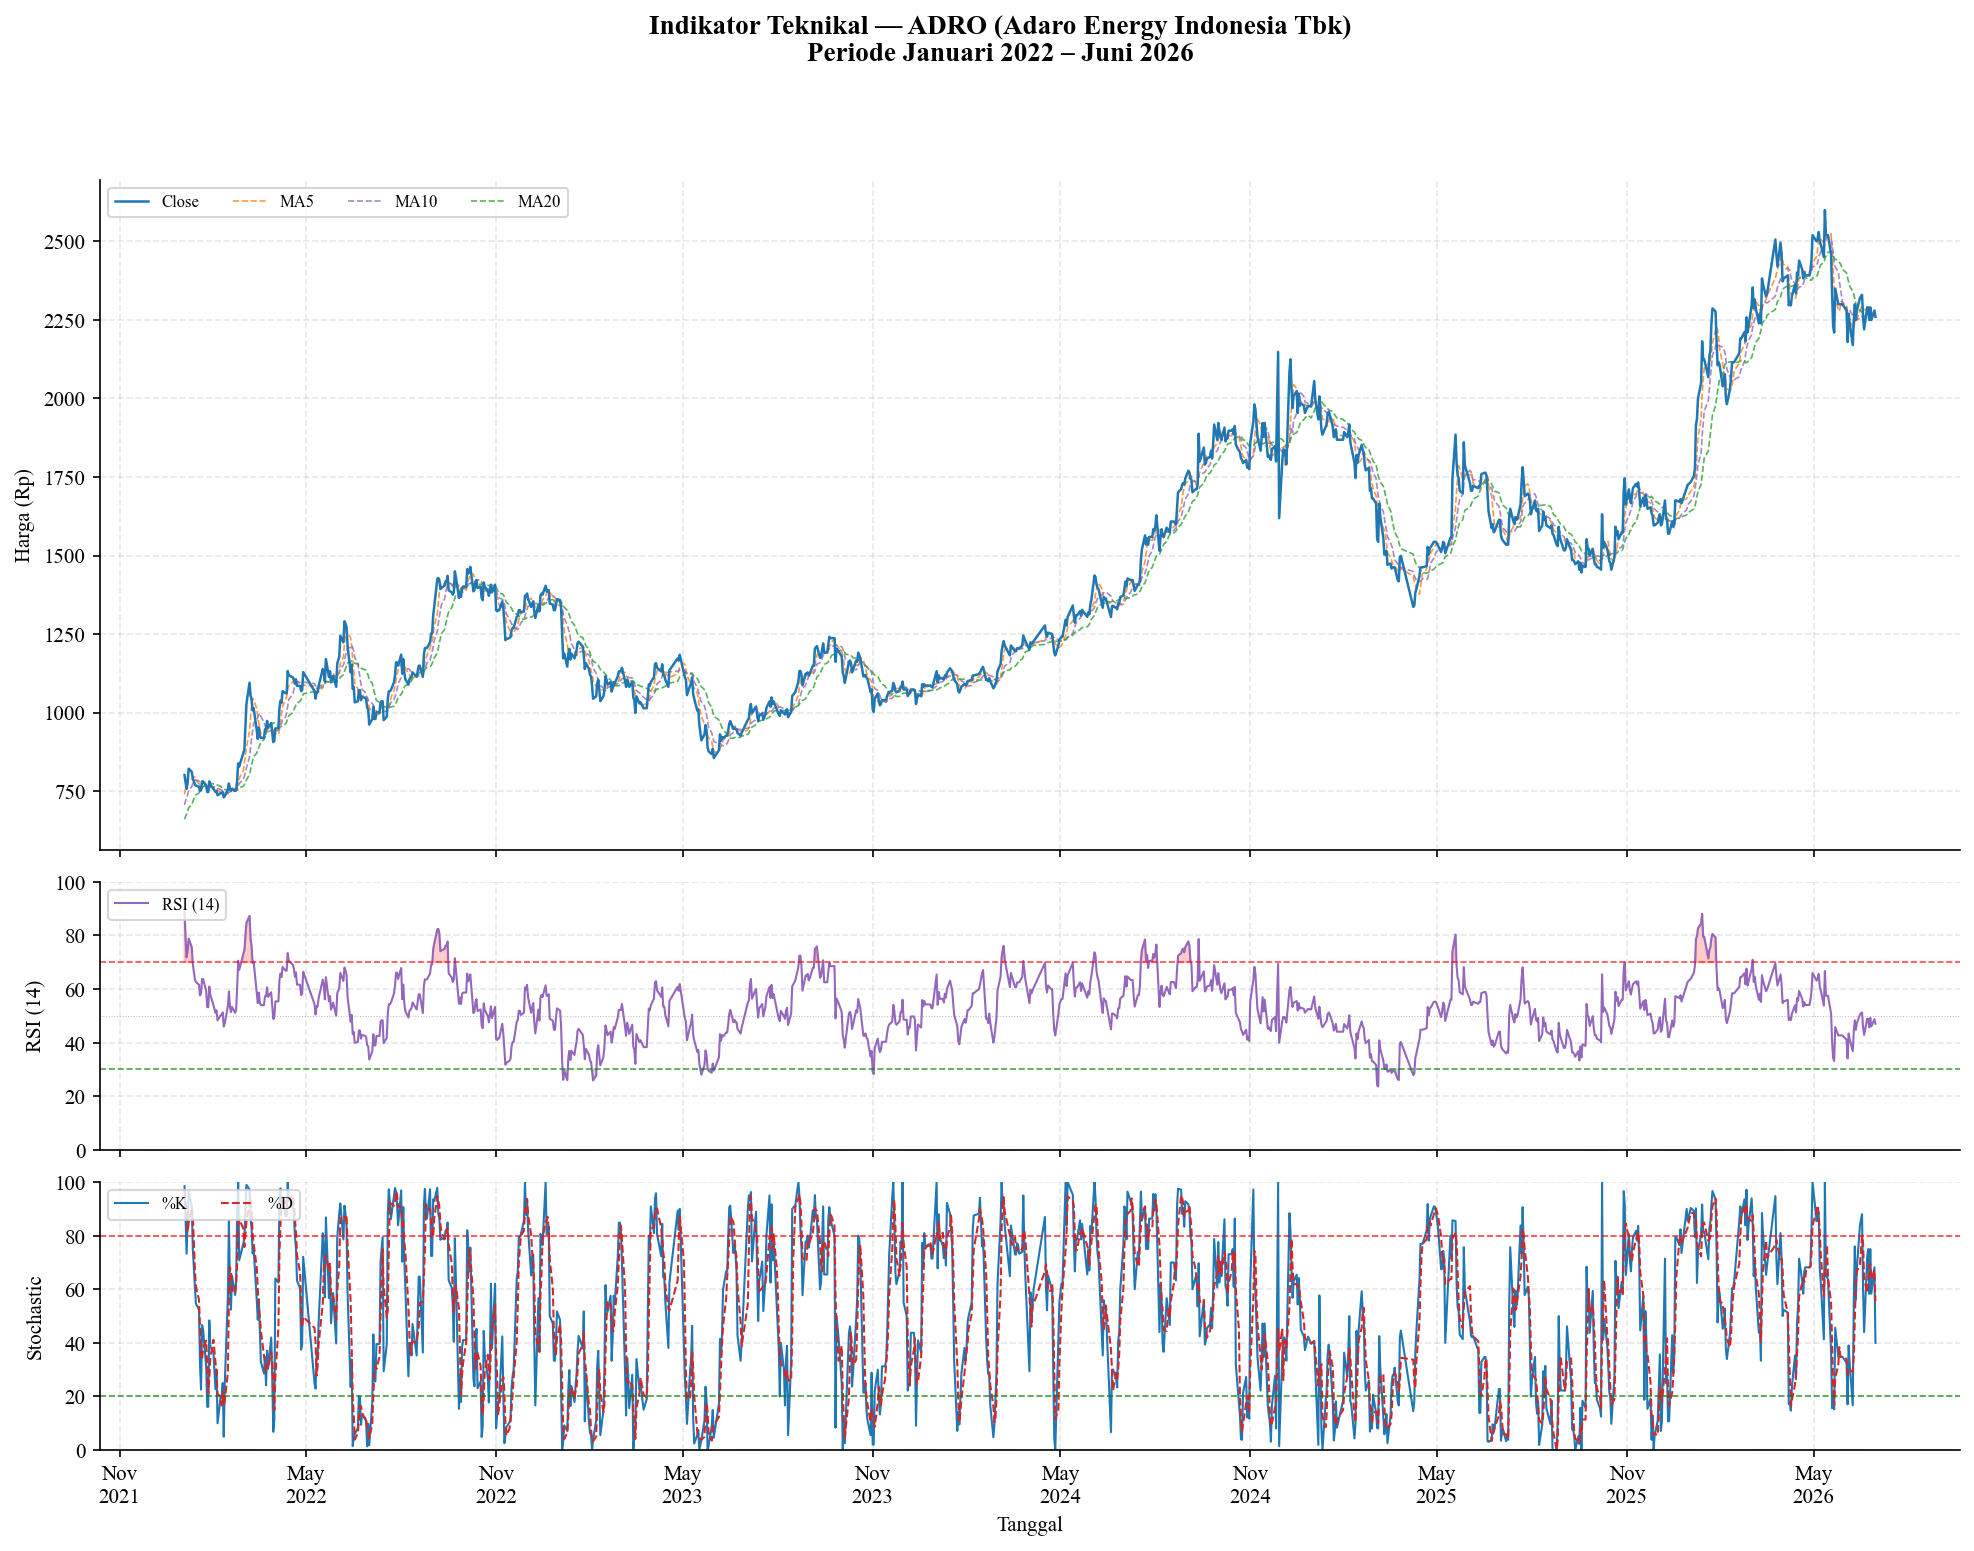

  ✅ Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\EDA\gambar_indikator_teknikal_ADRO.png


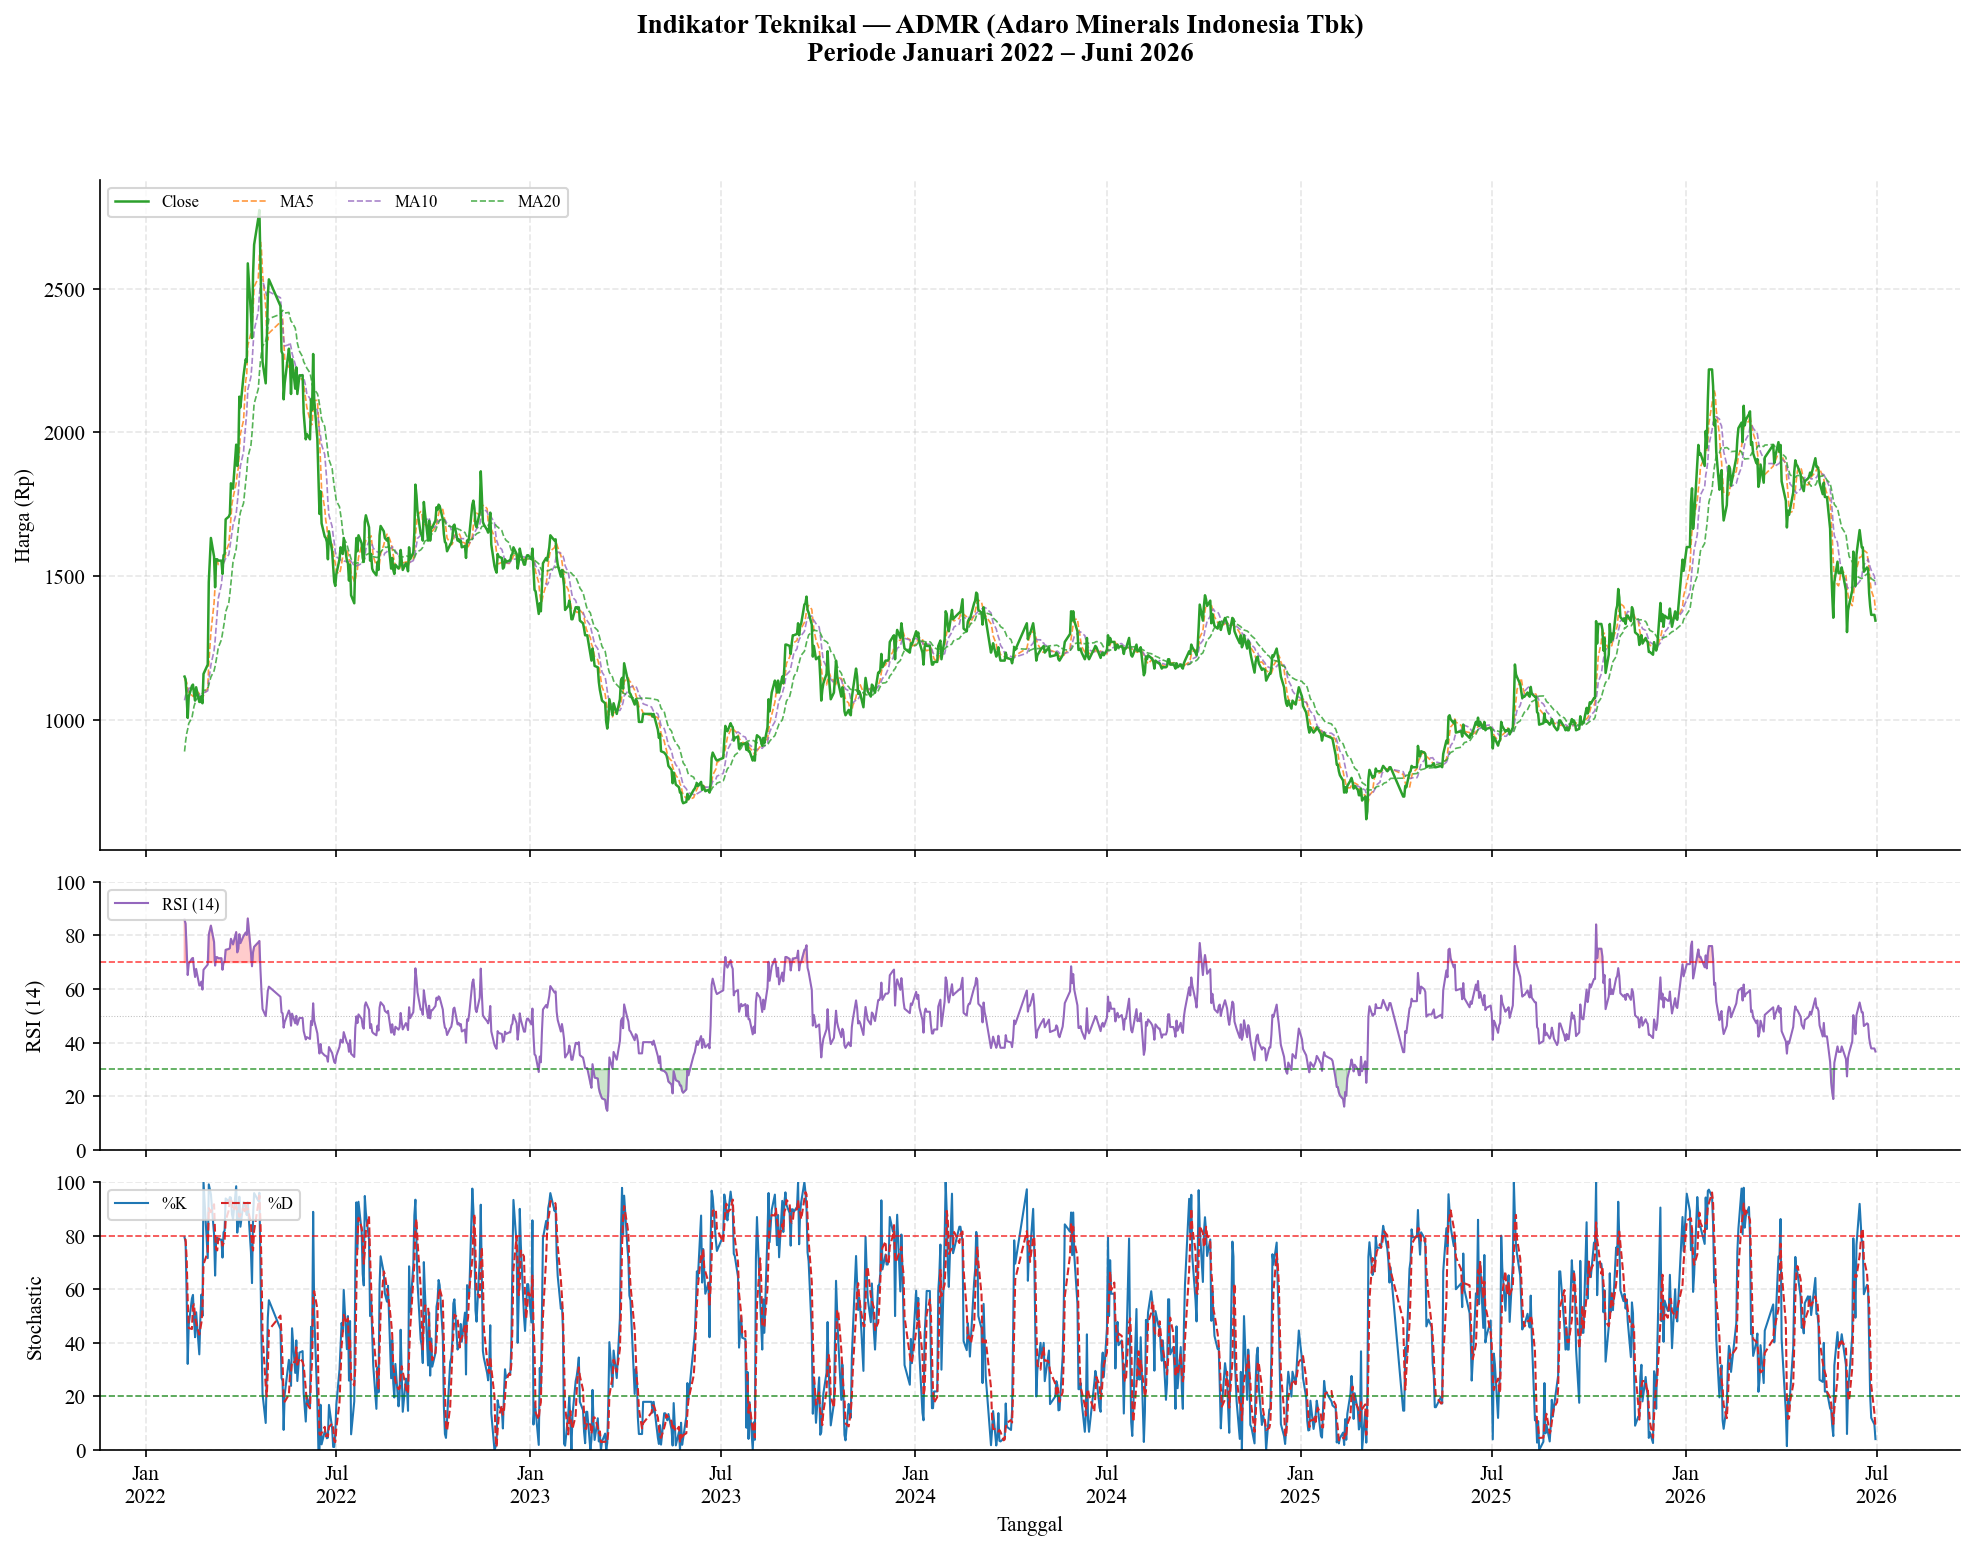

  ✅ Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\EDA\gambar_indikator_teknikal_ADMR.png


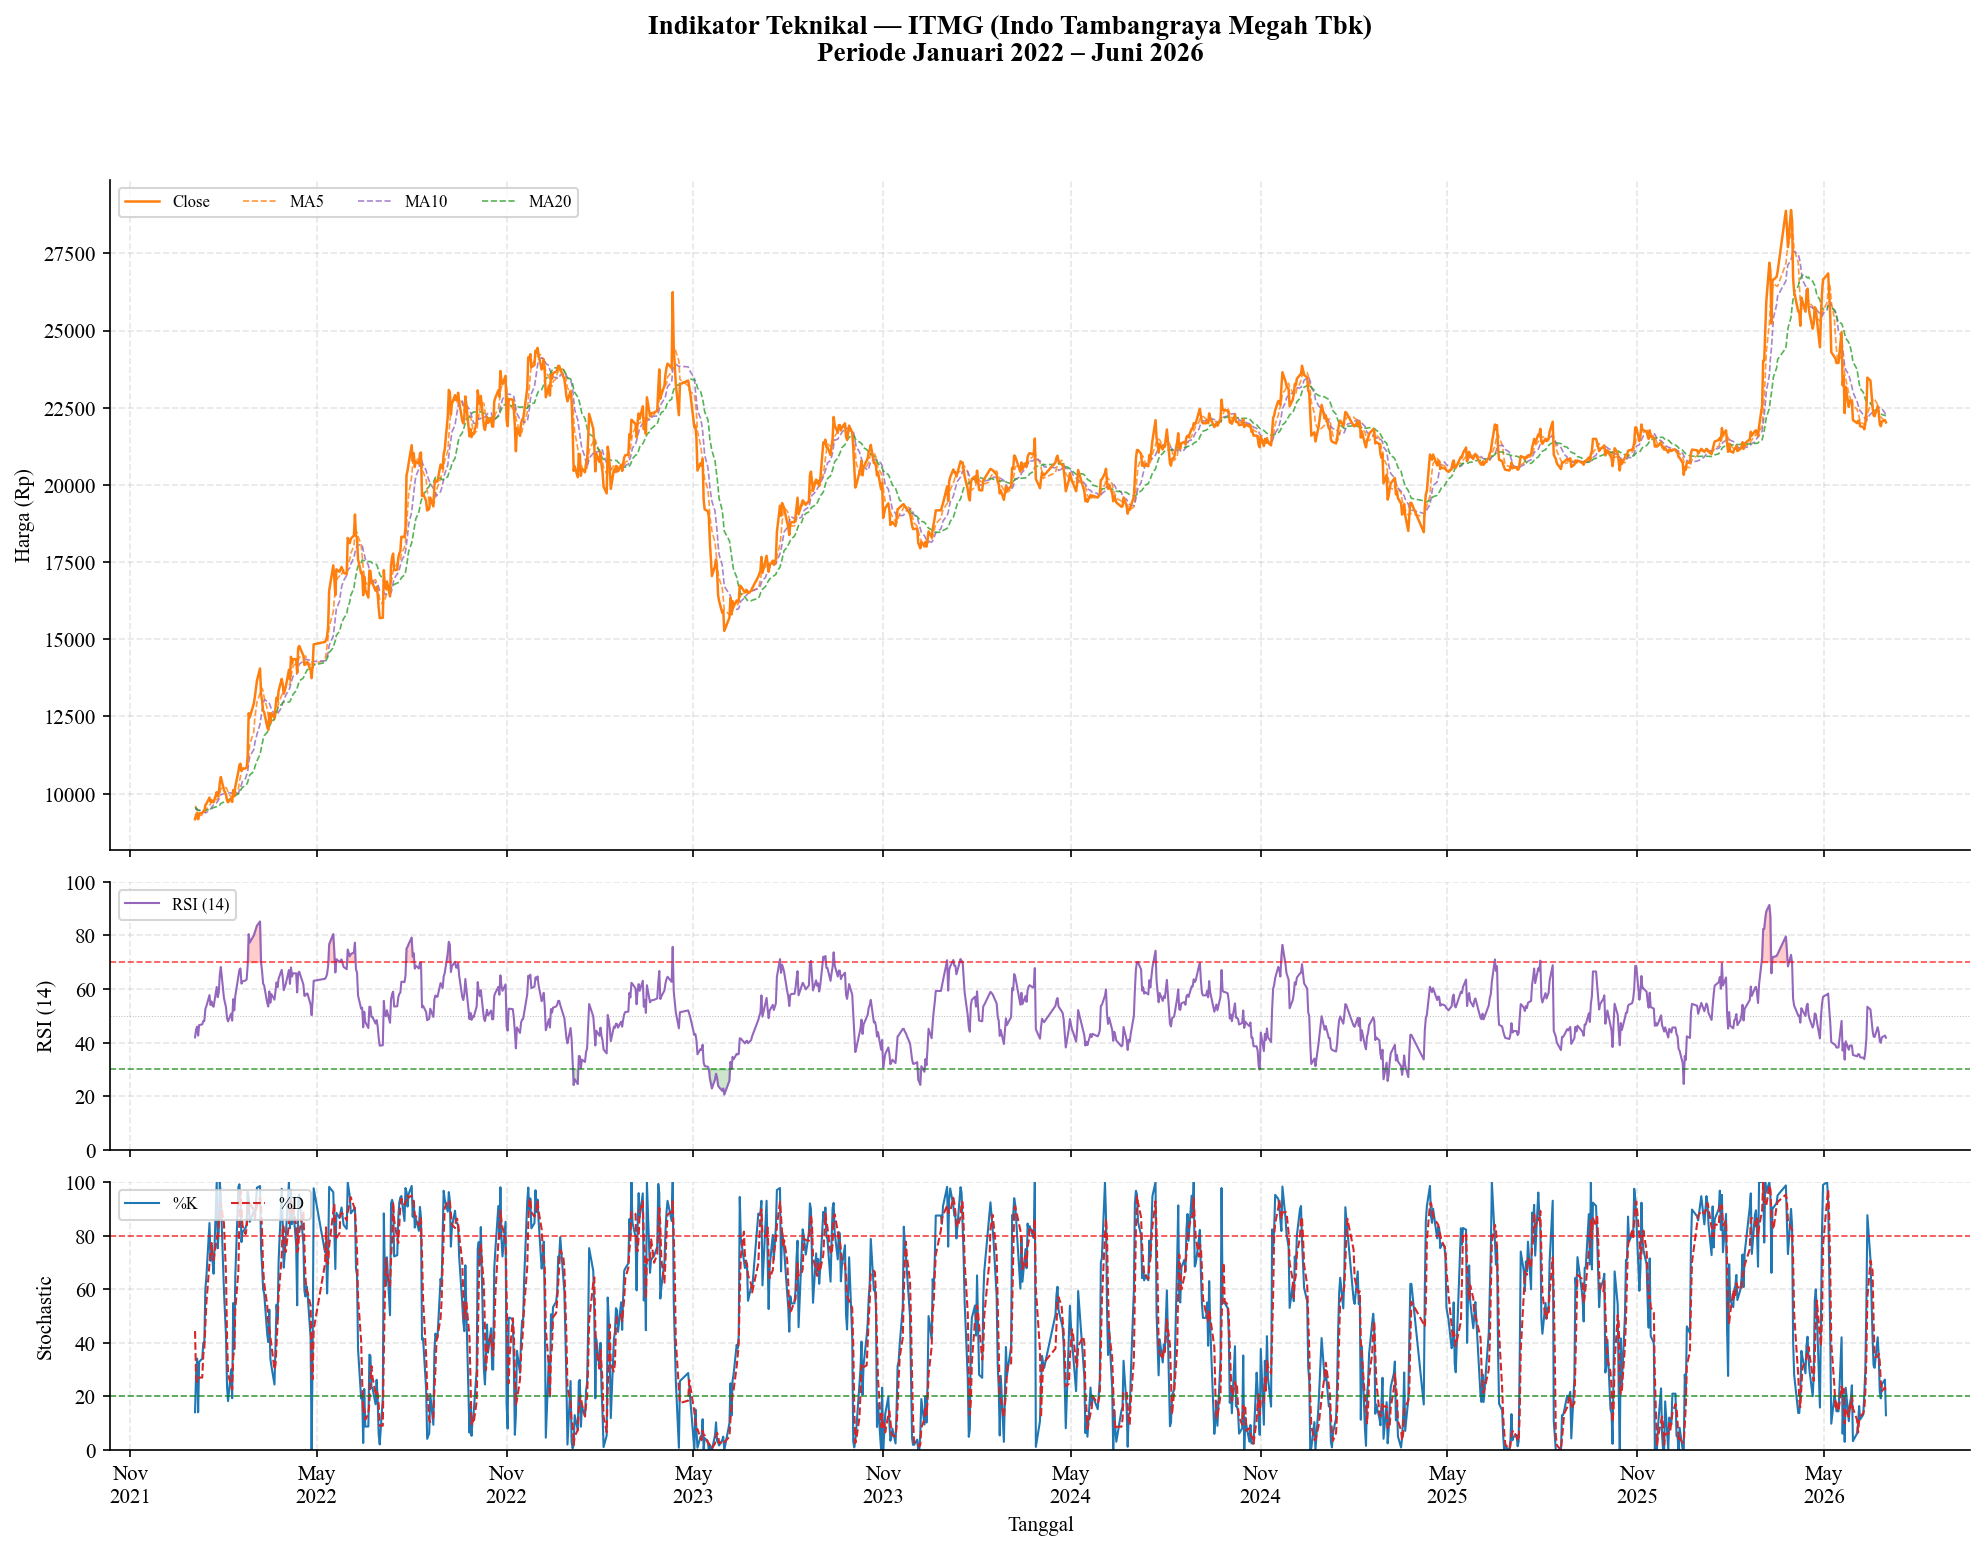

  ✅ Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\EDA\gambar_indikator_teknikal_ITMG.png


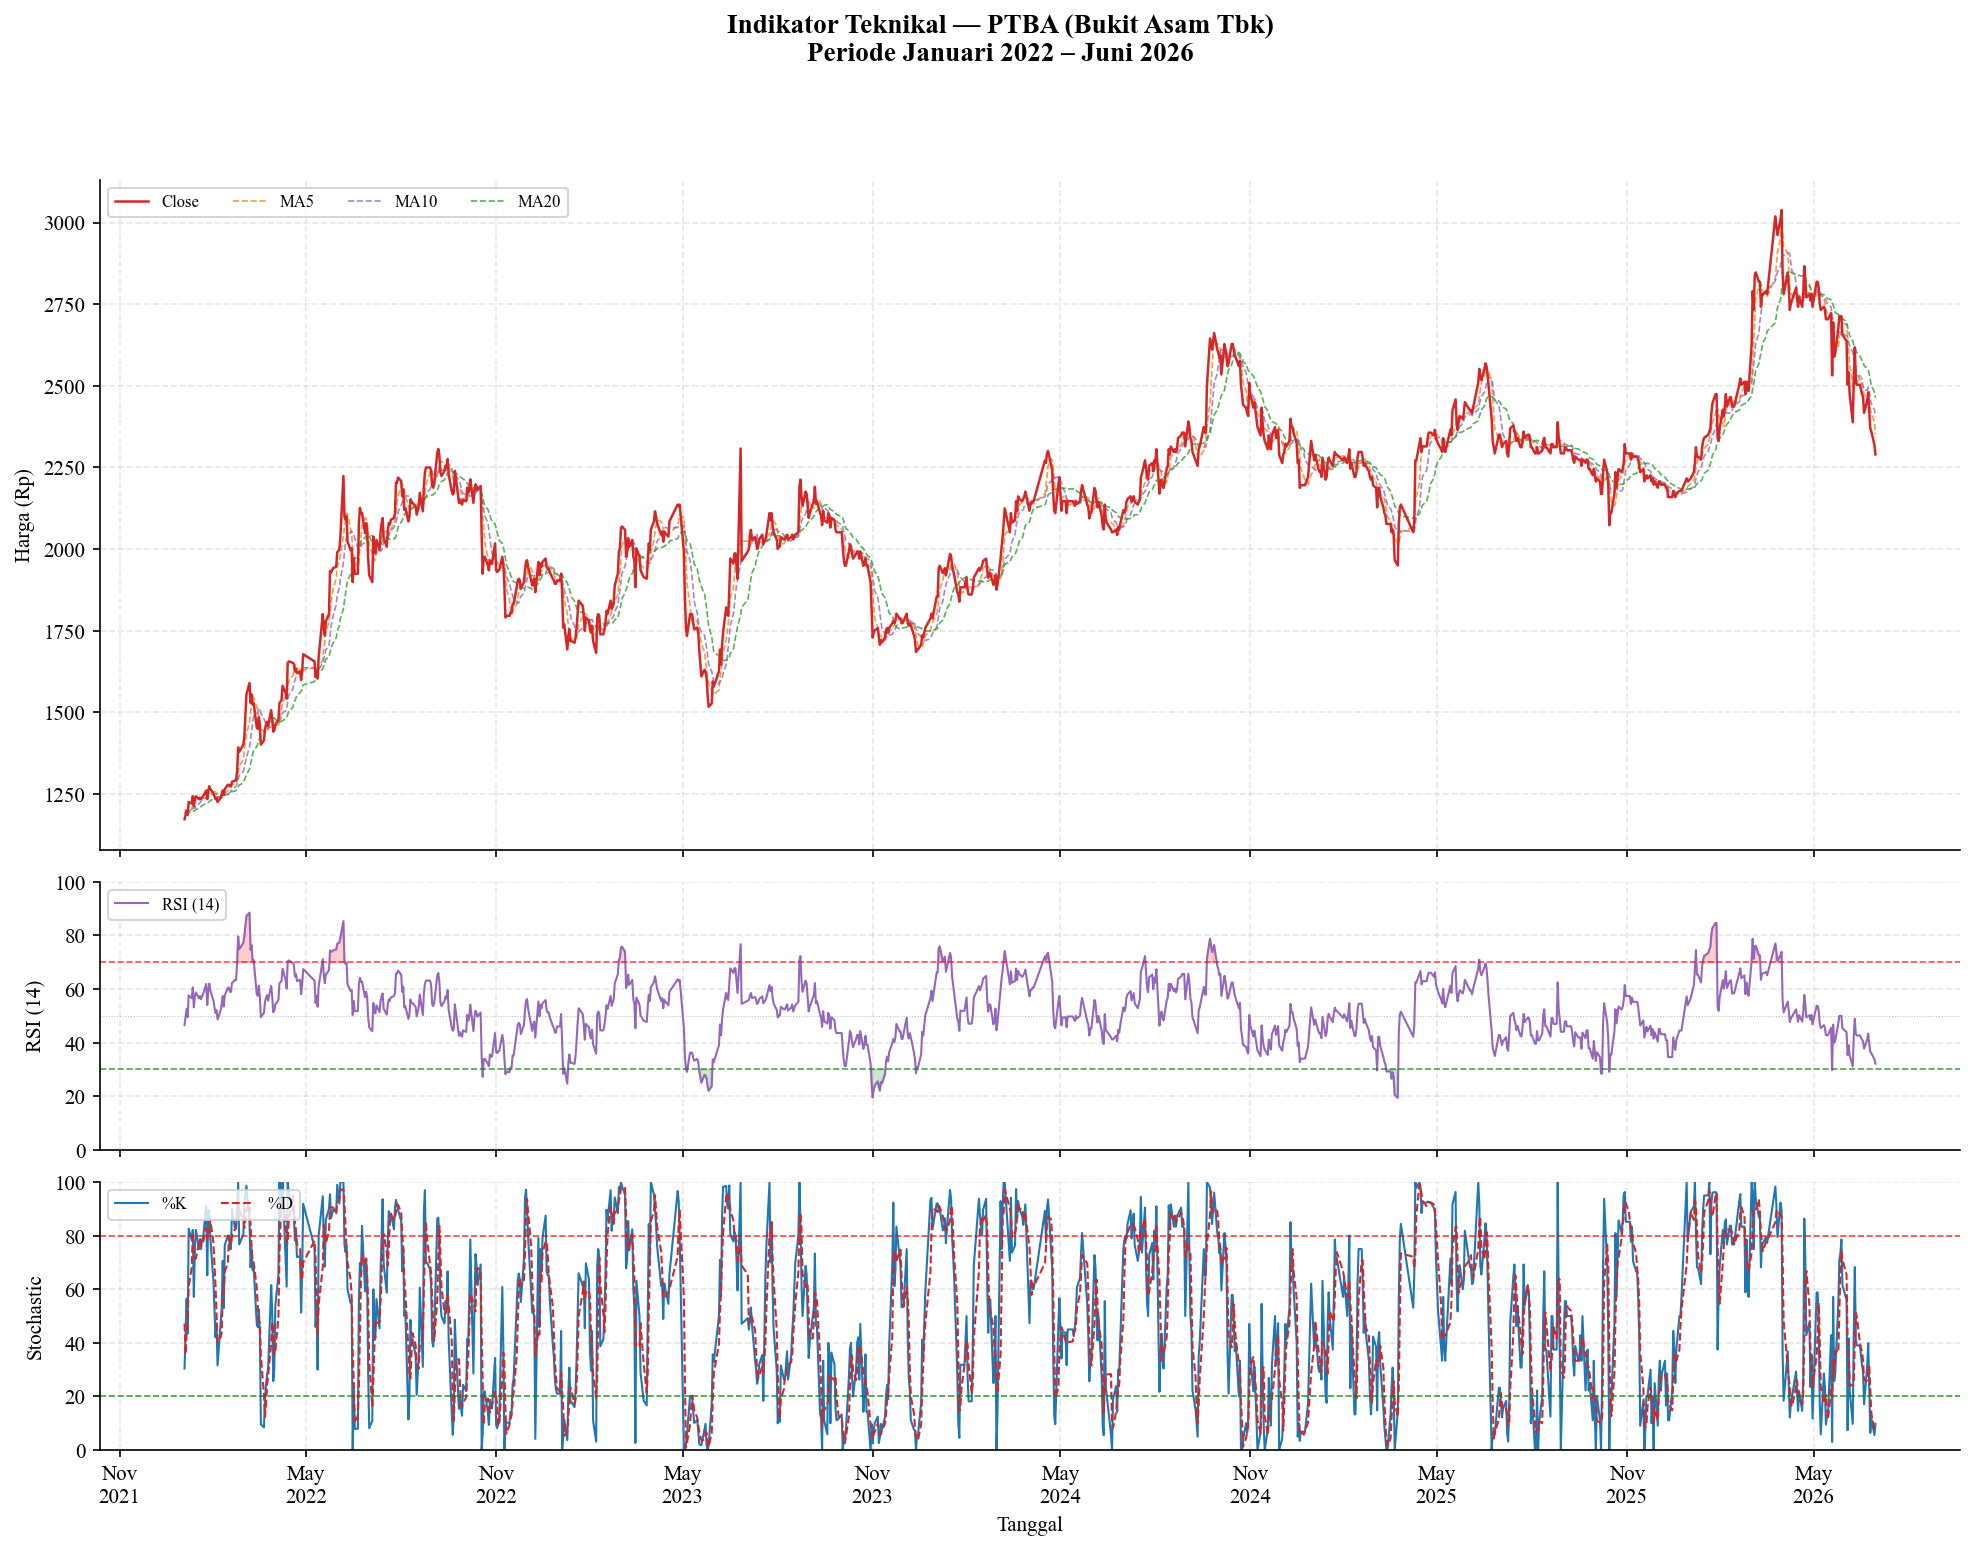

  ✅ Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\EDA\gambar_indikator_teknikal_PTBA.png


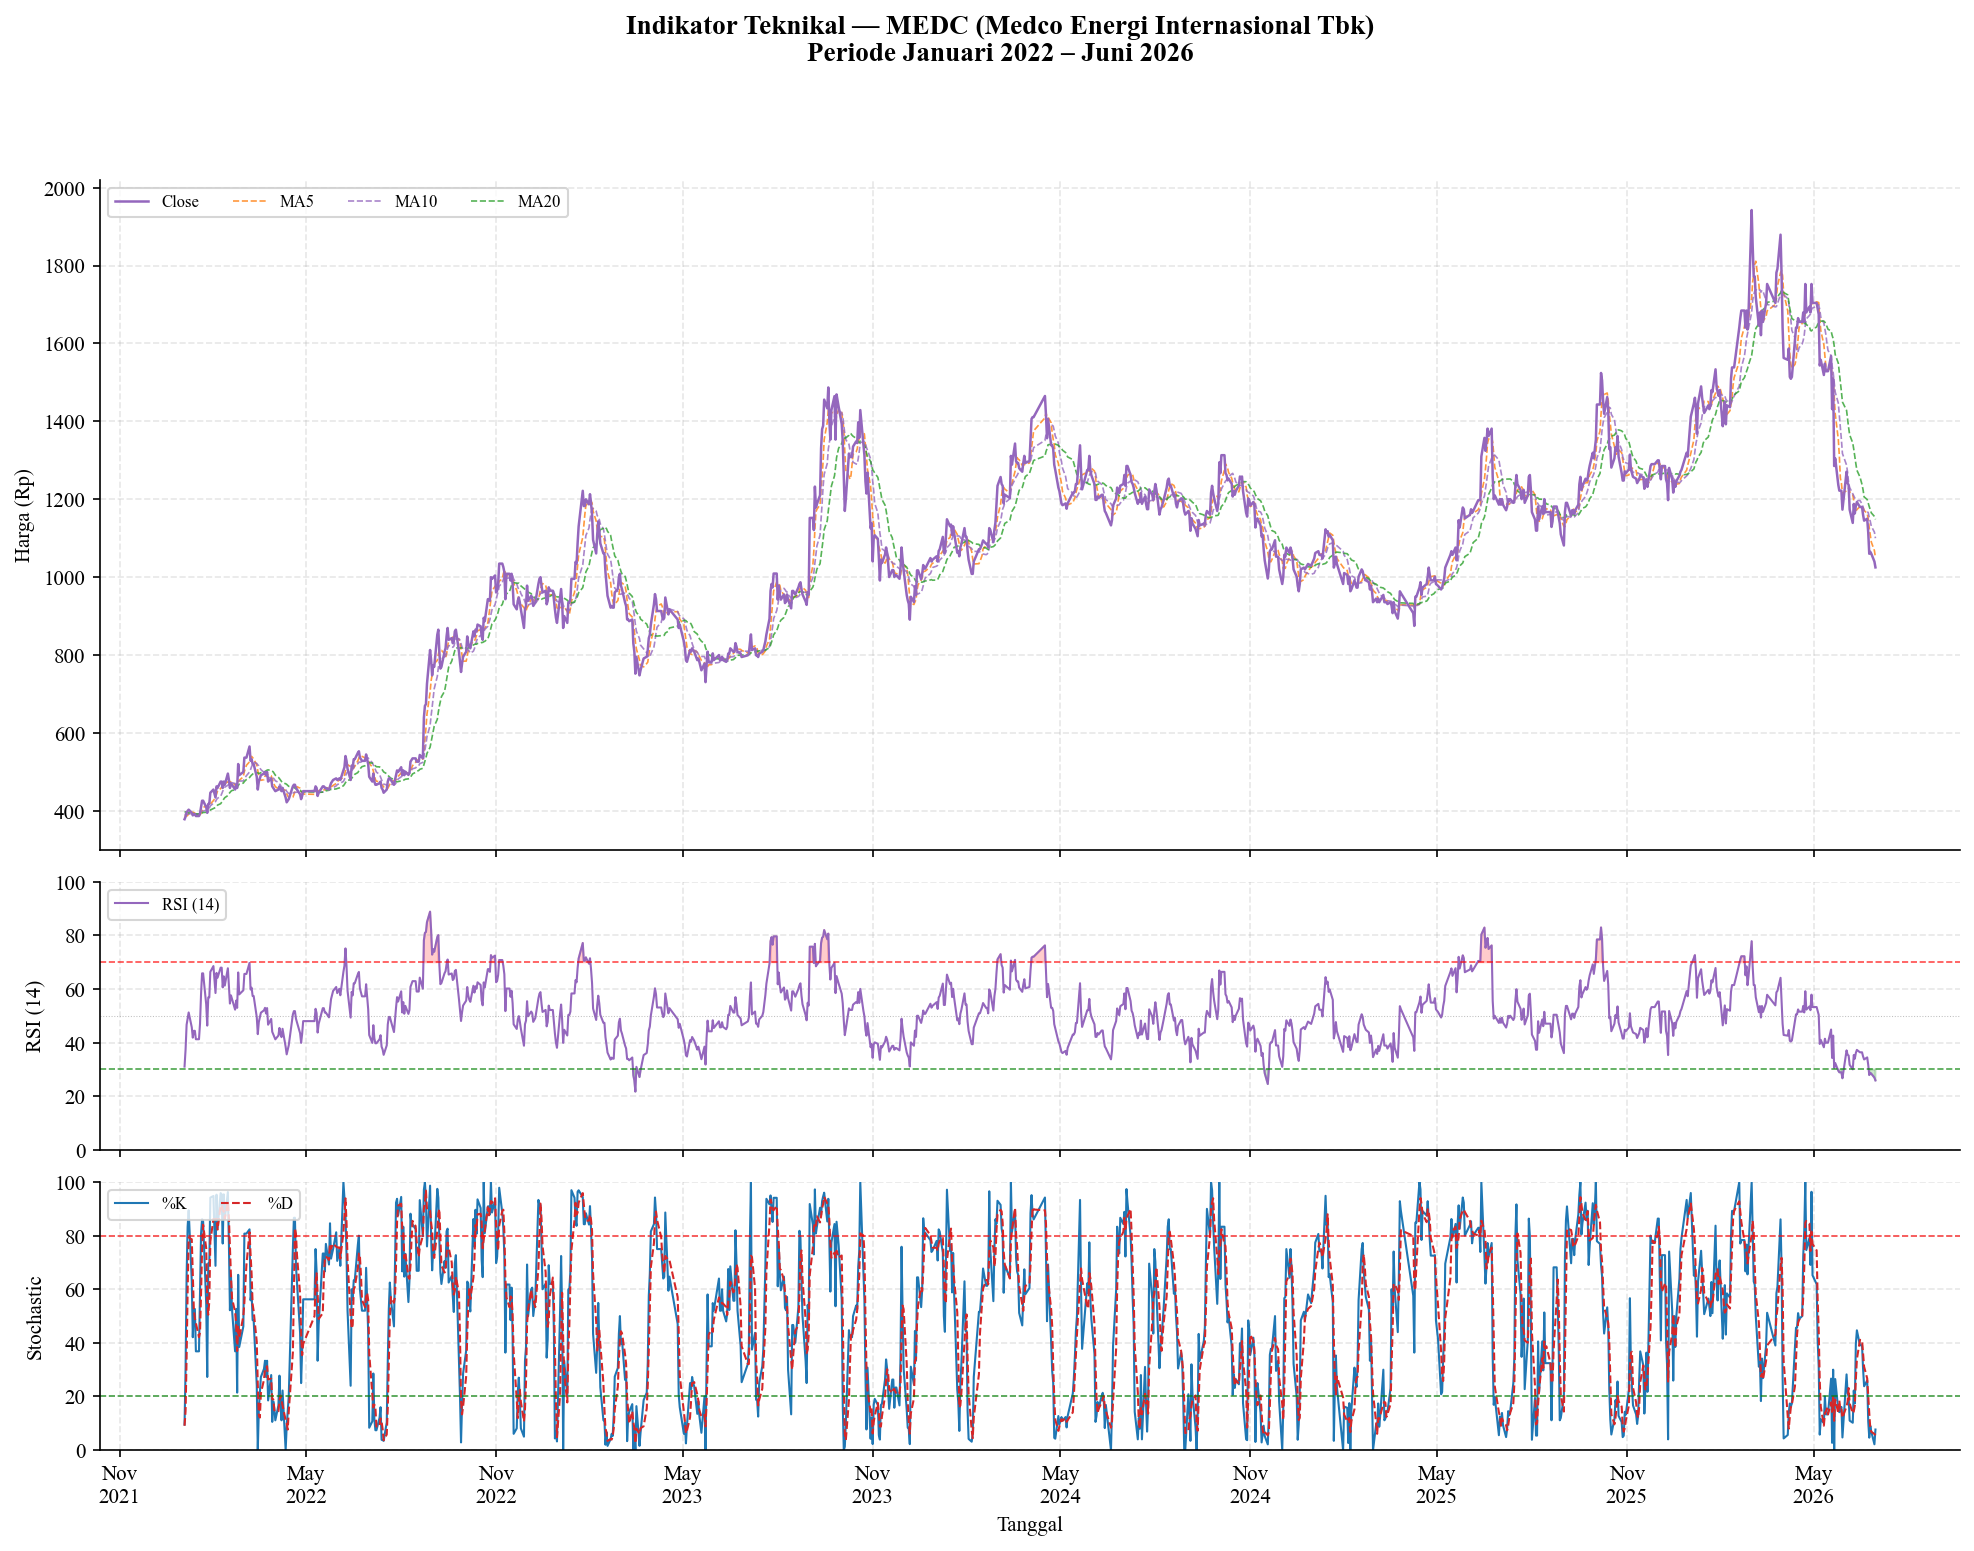

  ✅ Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\EDA\gambar_indikator_teknikal_MEDC.png


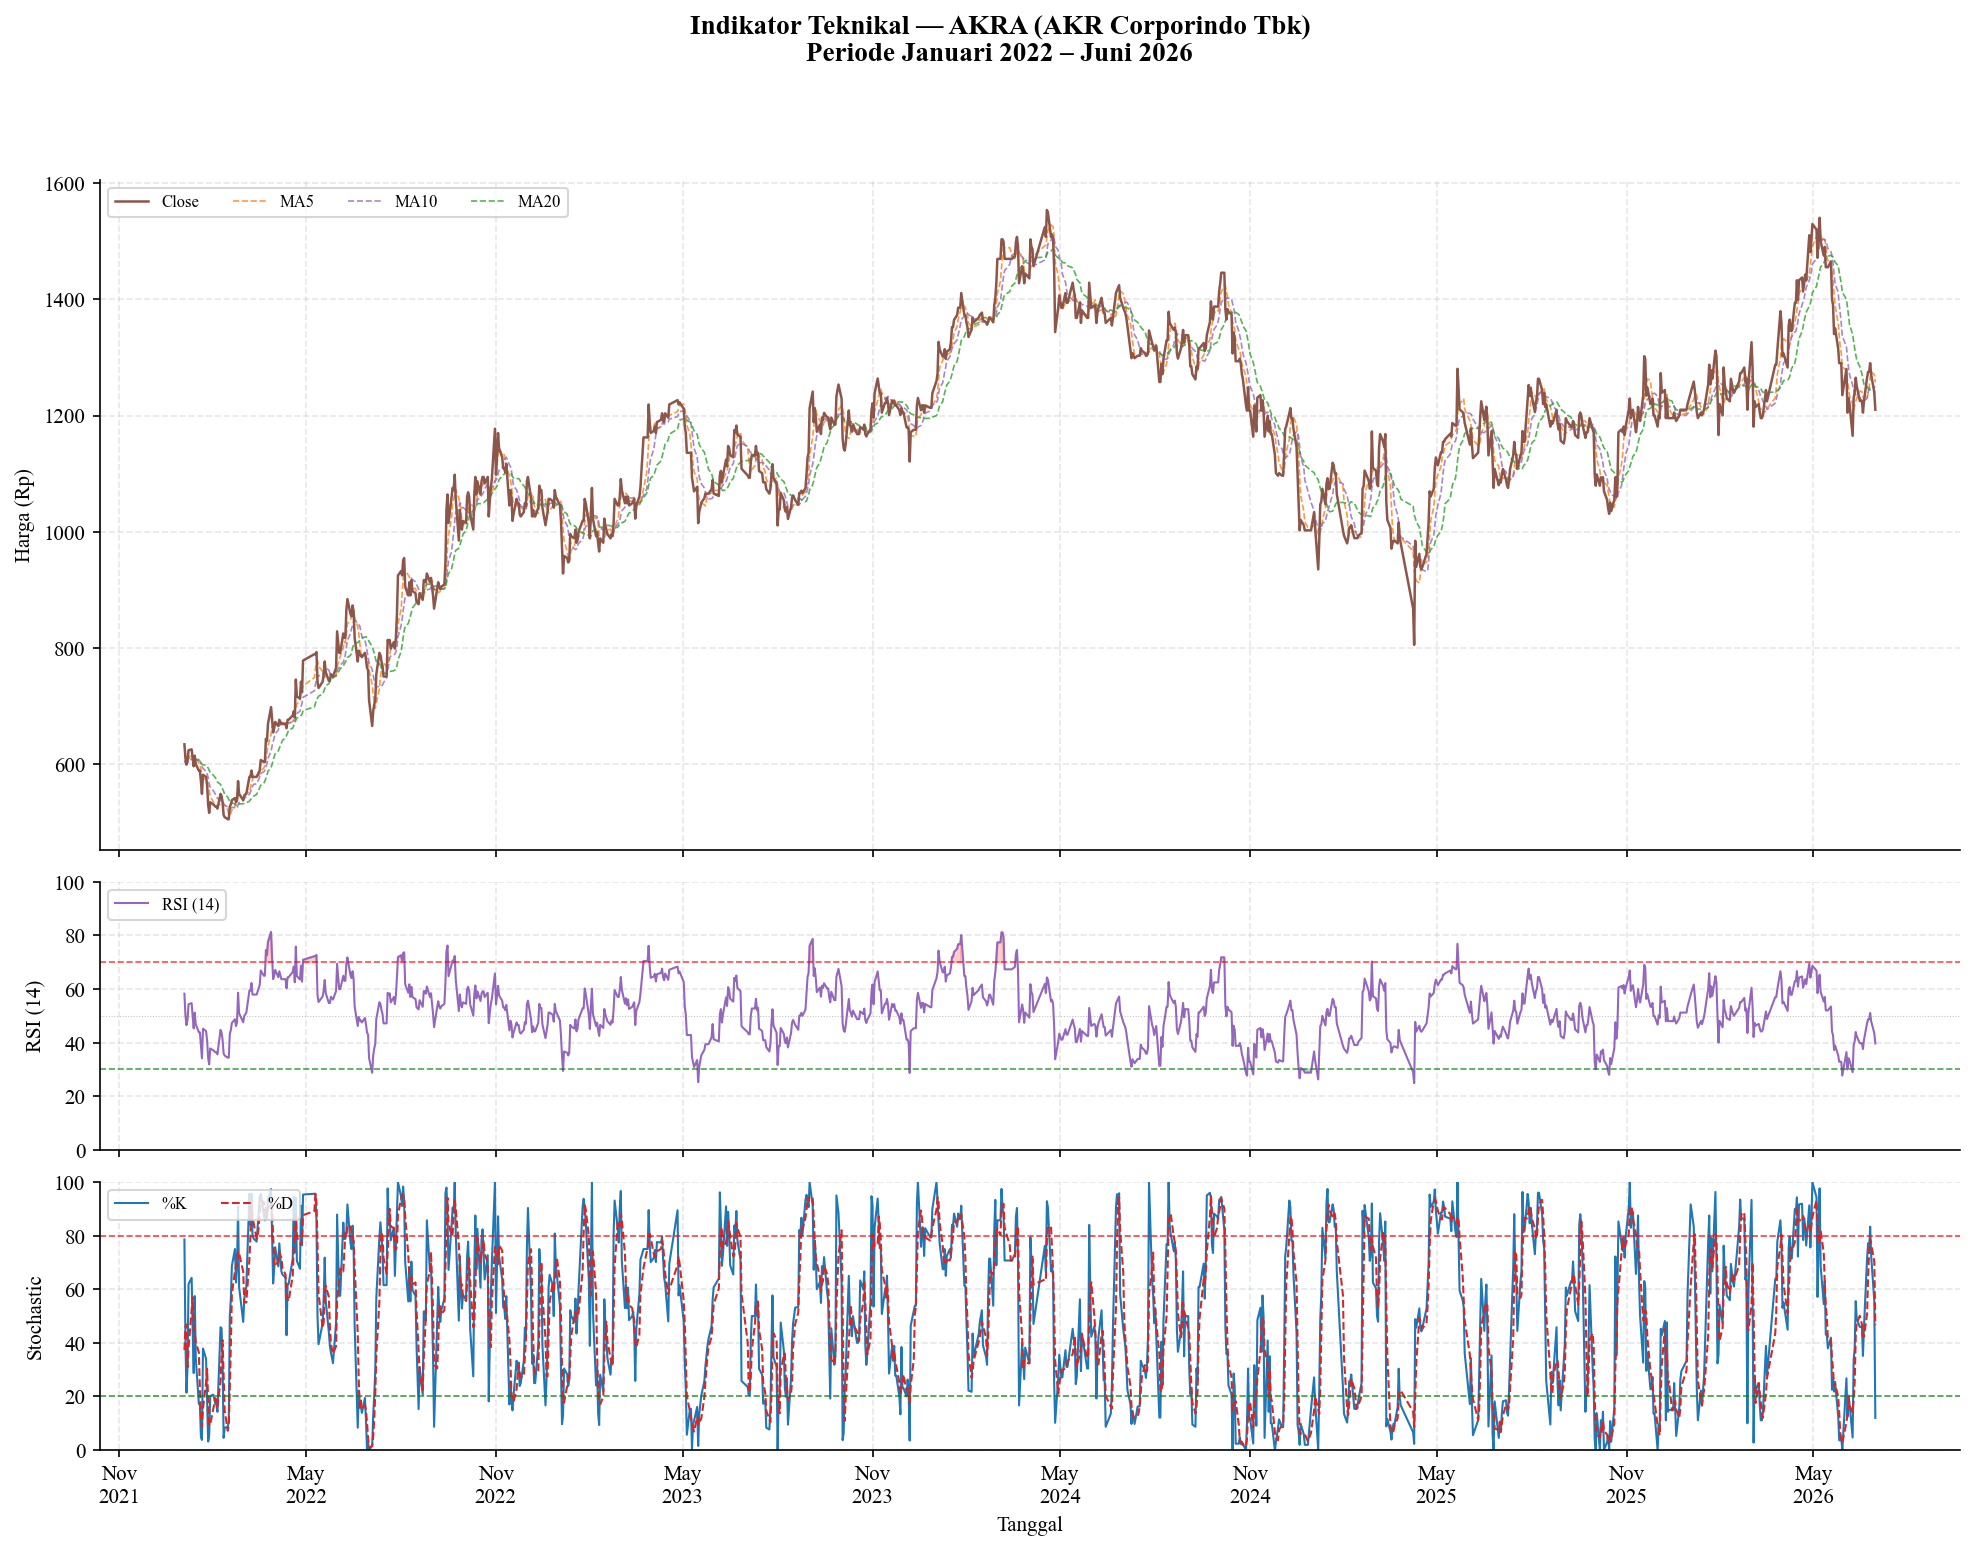

  ✅ Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\EDA\gambar_indikator_teknikal_AKRA.png


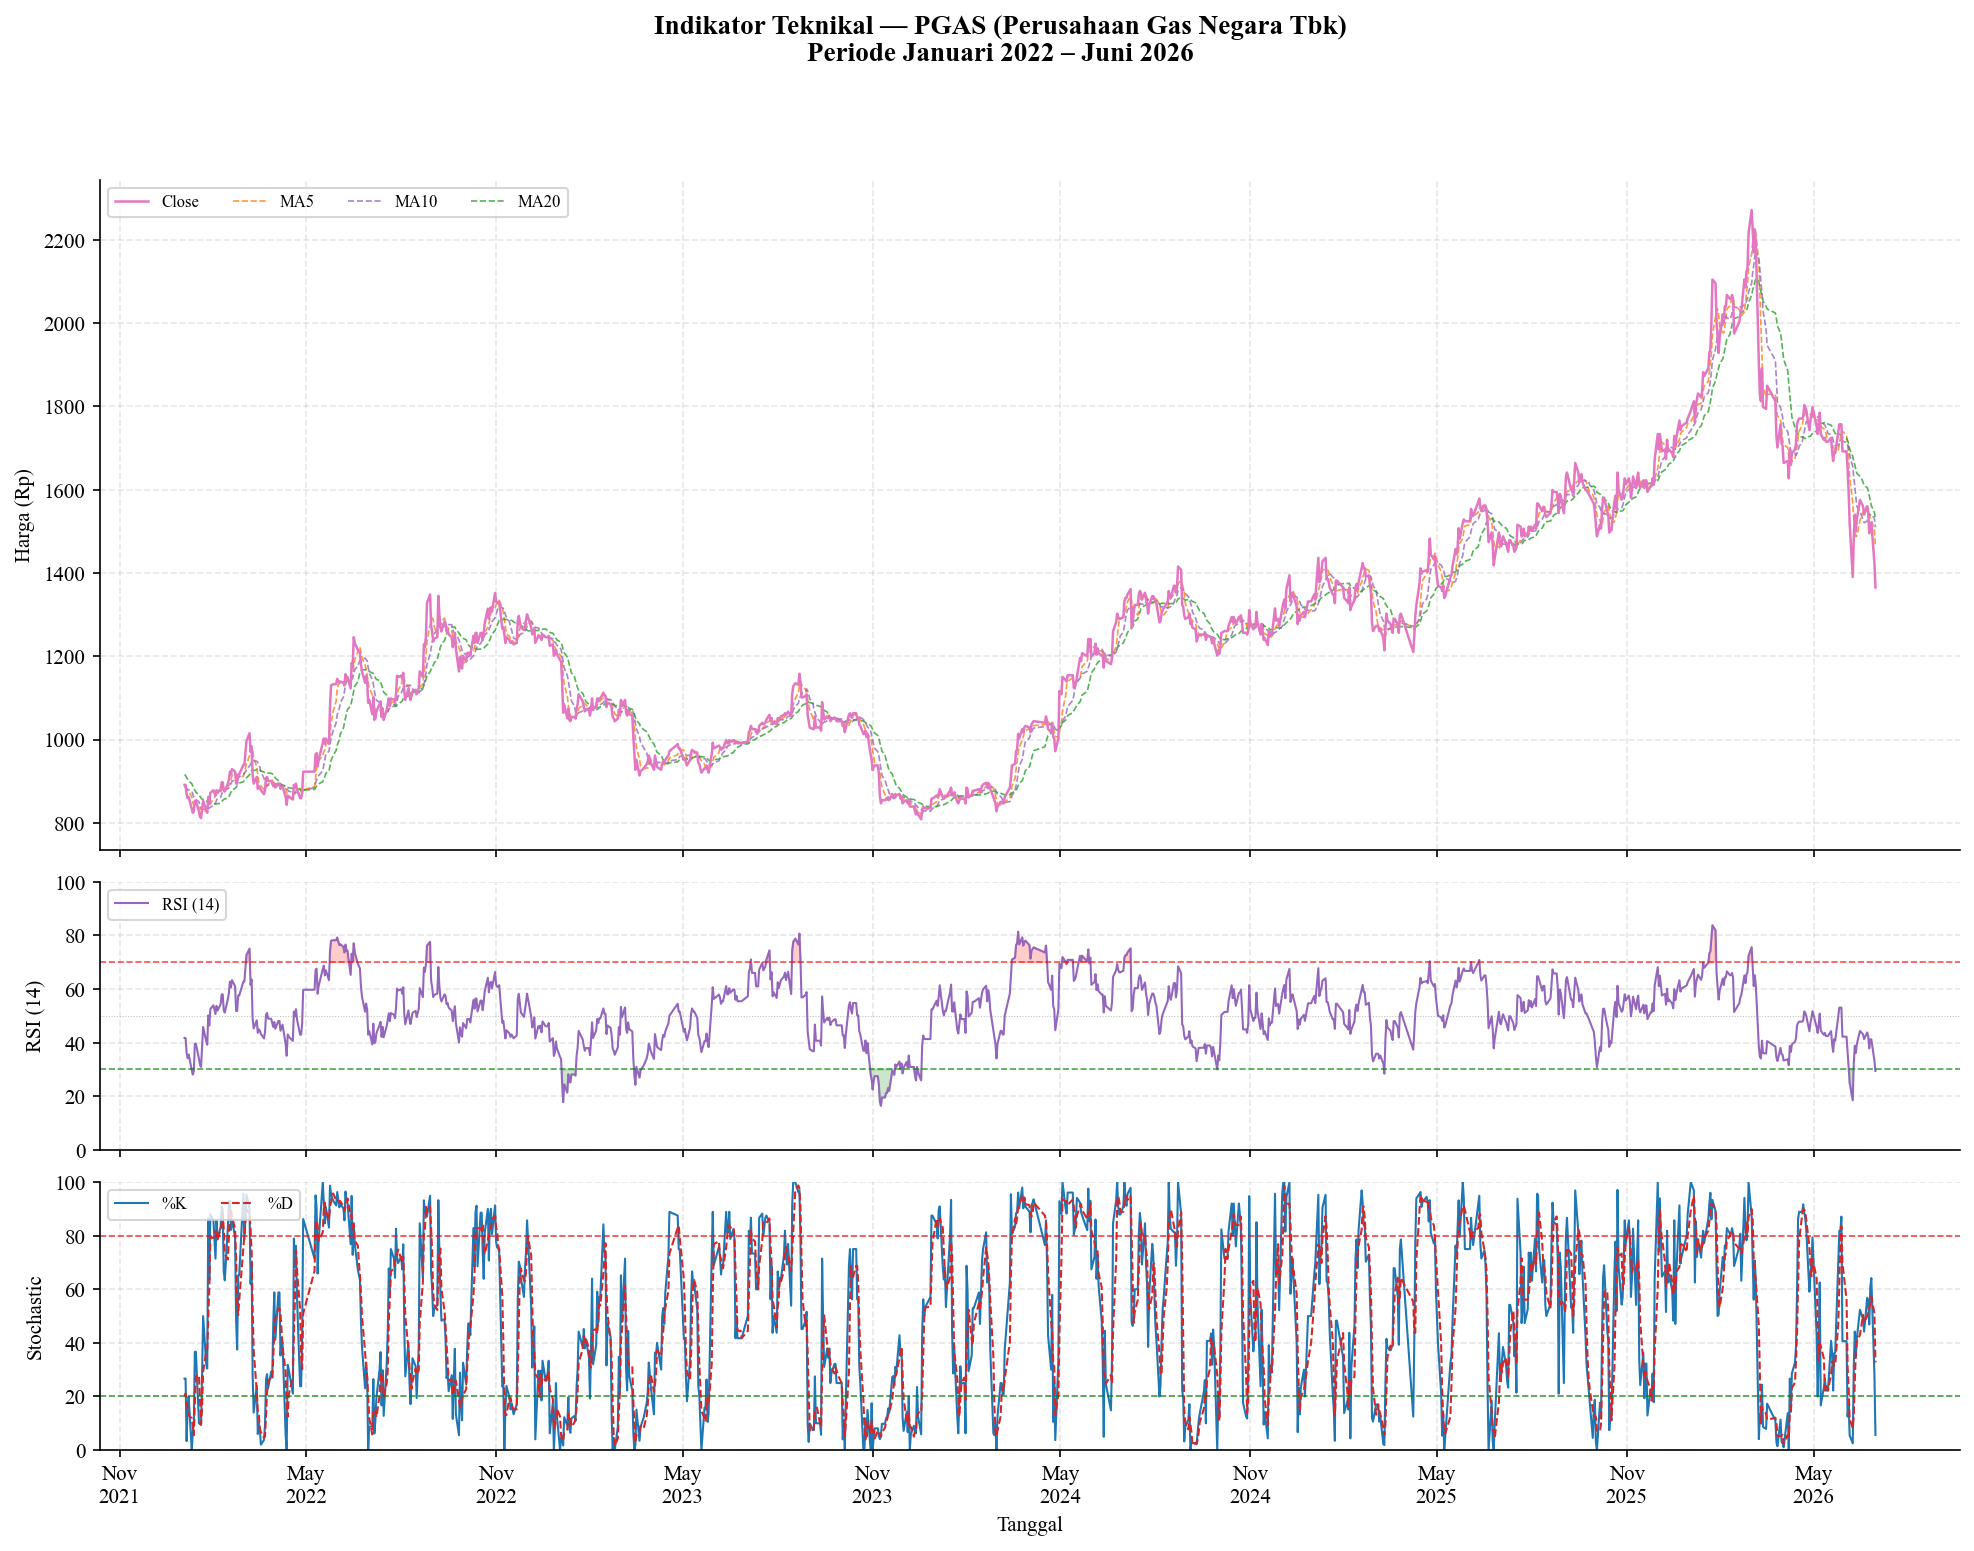

  ✅ Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\EDA\gambar_indikator_teknikal_PGAS.png


In [13]:
print('=' * 65)
print('  📊 VISUALISASI INDIKATOR TEKNIKAL PER EMITEN')
print('=' * 65)

import matplotlib.dates as mdates

for emiten in URUTAN_EMITEN:
    df_e = df_all[df_all['Emiten'] == emiten].copy()
    if df_e.empty:
        print(f'  ⚠️  {emiten}: Data kosong, skip')
        continue

    warna = WARNA_EMITEN.get(emiten, '#333333')
    nama  = NAMA_PERUSAHAAN.get(emiten, emiten)

    fig = plt.figure(figsize=(16, 11))
    fig.suptitle(
        f'Indikator Teknikal — {emiten} ({nama})\n'
        f'Periode Januari 2022 – Juni 2026',
        fontsize=13, fontweight='bold', y=0.98
    )

    gs = gridspec.GridSpec(3, 1, figure=fig,
                           height_ratios=[3, 1.2, 1.2],
                           hspace=0.08)

    ax1 = fig.add_subplot(gs[0])
    ax1.plot(df_e['Date'], df_e['Close'], color=warna, linewidth=1.2, label='Close', zorder=5)
    if 'MA5' in df_e.columns:
        ax1.plot(df_e['Date'], df_e['MA5'], color='#ff7f0e', linewidth=0.8, linestyle='--', label='MA5', alpha=0.8)
    if 'MA10' in df_e.columns:
        ax1.plot(df_e['Date'], df_e['MA10'], color='#9467bd', linewidth=0.8, linestyle='--', label='MA10', alpha=0.8)
    if 'MA20' in df_e.columns:
        ax1.plot(df_e['Date'], df_e['MA20'], color='#2ca02c', linewidth=0.8, linestyle='--', label='MA20', alpha=0.8)
    ax1.set_ylabel('Harga (Rp)', fontsize=10)
    ax1.legend(loc='upper left', fontsize=8, ncol=4)
    ax1.grid(alpha=0.3, linestyle='--')
    ax1.spines[['top','right']].set_visible(False)
    ax1.tick_params(labelbottom=False)

    ax2 = fig.add_subplot(gs[1], sharex=ax1)
    if 'RSI14' in df_e.columns:
        ax2.plot(df_e['Date'], df_e['RSI14'], color='#9467bd', linewidth=1.0, label='RSI (14)')
        ax2.axhline(70, color='red', linewidth=0.8, linestyle='--', alpha=0.7)
        ax2.axhline(30, color='green', linewidth=0.8, linestyle='--', alpha=0.7)
        ax2.axhline(50, color='gray', linewidth=0.5, linestyle=':', alpha=0.5)
        ax2.fill_between(df_e['Date'], df_e['RSI14'], 70, where=df_e['RSI14'] >= 70, alpha=0.2, color='red')
        ax2.fill_between(df_e['Date'], df_e['RSI14'], 30, where=df_e['RSI14'] <= 30, alpha=0.2, color='green')
        ax2.set_ylim(0, 100)
    ax2.set_ylabel('RSI (14)', fontsize=10)
    ax2.legend(loc='upper left', fontsize=8)
    ax2.grid(alpha=0.3, linestyle='--')
    ax2.spines[['top','right']].set_visible(False)
    ax2.tick_params(labelbottom=False)

    ax3 = fig.add_subplot(gs[2], sharex=ax1)
    if 'Stoch_K' in df_e.columns and 'Stoch_D' in df_e.columns:
        ax3.plot(df_e['Date'], df_e['Stoch_K'], color='#1f77b4', linewidth=1.0, label='%K')
        ax3.plot(df_e['Date'], df_e['Stoch_D'], color='#d62728', linewidth=1.0, linestyle='--', label='%D')
        ax3.axhline(80, color='red', linewidth=0.8, linestyle='--', alpha=0.7)
        ax3.axhline(20, color='green', linewidth=0.8, linestyle='--', alpha=0.7)
        ax3.set_ylim(0, 100)
    ax3.set_ylabel('Stochastic', fontsize=10)
    ax3.set_xlabel('Tanggal', fontsize=10)
    ax3.legend(loc='upper left', fontsize=8, ncol=2)
    ax3.grid(alpha=0.3, linestyle='--')
    ax3.spines[['top','right']].set_visible(False)

    ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax3.xaxis.set_major_locator(mdates.MonthLocator(interval=6))

    plt.tight_layout(rect=[0, 0, 1, 0.96])

    path_gambar = DIR_GAMBAR / f'gambar_indikator_teknikal_{emiten}.png'
    plt.savefig(path_gambar, dpi=200, bbox_inches='tight')
    plt.show()
    print(f'  ✅ Gambar disimpan: {path_gambar}')
    plt.close()


---
## CELL 10 - Definisi X1 Final & Simpan Dataset Teknikal

Menyimpan **seluruh kolom** (termasuk kolom referensi Open/High/Low/Close/Volume/MA level untuk EDA Bab 4) ke `technical_features.csv`, disertai metadata JSON berisi daftar `KOLOM_X1_FINAL` yang menjadi input X pada notebook modeling berikutnya.

**Catatan untuk notebook modeling:**
- Kolom `Volatilitas` ($\sigma_t$) berstatus kolom referensi untuk EDA, bukan fitur input model.
- Hanya `Volatilitas_Target` ($\sigma_{t+1}$) yang menjadi Y.
- Pembagian data wajib kronologis 80:20 tanpa `shuffle`.


In [14]:
print('=' * 70)
print('  CELL 10 - SIMPAN DATASET TEKNIKAL FINAL')
print('=' * 70)

KOLOM_X1_FINAL = [
    'Log_Return',
    'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5',
    'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio',
    'RSI14', 'Stoch_K', 'Stoch_D', 'Volume_ZScore',
    'R_Exit', 'GARCH_Forecast',            # [v4] fitur hybrid GARCH
]
KOLOM_Y = 'Volatilitas_Target'
KOLOM_REFERENSI = ['Open', 'High', 'Low', 'Close', 'Volume',
                   'MA5', 'MA10', 'MA20', 'Volatilitas']
KOLOM_KUNCI = ['Date', 'Emiten']

print(f'X1 FINAL ({len(KOLOM_X1_FINAL)} fitur):')
for i, k in enumerate(KOLOM_X1_FINAL, 1):
    print(f'   {i:>2}. {k}')
print(f'\nY  : {KOLOM_Y}  (= volatilitas t+1)')
print(f'Ref: {KOLOM_REFERENSI}  (bukan X, untuk EDA Bab 4)')
print()

df_save = df_all.copy()
df_save['Date'] = pd.to_datetime(df_save['Date']).dt.strftime('%Y-%m-%d')

path_output = DIR_PROCESSED / 'technical_features.csv'
df_save.to_csv(path_output, index=False, encoding='utf-8-sig')

# -- metadata JSON untuk notebook modeling (XGBoost/LSTM)
import json as _json
path_meta = DIR_PROCESSED / 'technical_features_meta.json'
with open(path_meta, 'w', encoding='utf-8') as f:
    _json.dump({
        'versi': 'v4 (lag relatif target + fitur hybrid GARCH)',
        'kolom_x1': KOLOM_X1_FINAL,
        'kolom_y': KOLOM_Y,
        'kolom_referensi': KOLOM_REFERENSI,
        'kolom_kunci': KOLOM_KUNCI,
        'periode_awal': str(df_all['Date'].min().date()),
        'periode_akhir': str(df_all['Date'].max().date()),
        'n_baris': int(len(df_all)),
        'n_emiten': int(df_all['Emiten'].nunique()),
        'desain_target': 'forecast t+1 (Volatilitas.shift(-1))',
        'catatan_split': 'Time-series split kronologis 80:20, tanpa shuffle',
    }, f, ensure_ascii=False, indent=2)

print(f'SAVE PATH     : {path_output.resolve()}')
print(f'METADATA X1/Y : {path_meta.resolve()}')
print(f'Total baris   : {len(df_save):,}')
print(f'Total kolom   : {len(df_save.columns)}')
print(f'Hari/emiten   : {len(df_save) // df_save["Emiten"].nunique():,}')

# -- VALIDASI RELOAD
cek = pd.read_csv(path_output)
assert len(cek) == len(df_save), '[X] Jumlah baris hasil reload tidak cocok'
assert all(c in cek.columns for c in KOLOM_X1_FINAL + [KOLOM_Y]), \
    '[X] Ada kolom X1/Y yang hilang setelah reload'
print('\n[OK] Validasi reload lolos. Kolom hasil reload:')
print(cek.columns.tolist())


  CELL 10 - SIMPAN DATASET TEKNIKAL FINAL
X1 FINAL (15 fitur):
    1. Log_Return
    2. Vol_Lag1
    3. Vol_Lag2
    4. Vol_Lag3
    5. Vol_MA5
    6. Vol_STD5
    7. MA5_Ratio
    8. MA10_Ratio
    9. MA20_Ratio
   10. RSI14
   11. Stoch_K
   12. Stoch_D
   13. Volume_ZScore
   14. R_Exit
   15. GARCH_Forecast

Y  : Volatilitas_Target  (= volatilitas t+1)
Ref: ['Open', 'High', 'Low', 'Close', 'Volume', 'MA5', 'MA10', 'MA20', 'Volatilitas']  (bukan X, untuk EDA Bab 4)

SAVE PATH     : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\technical_features.csv
METADATA X1/Y : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\technical_features_meta.json
Total baris   : 7,494
Total kolom   : 27
Hari/emiten   : 1,070

[OK] Validasi reload lolos. Kolom hasil reload:
['Date', 'Emiten', 'Open', 'Close', 'Hig

In [15]:
# ==============================================================================
# CELL — TABEL CONTOH HASIL CELL 3 (FITUR DASAR) — SAMPEL PERTENGAHAN
# (Log Return, Volatilitas+Target, MA/Rasio, Stochastic)
# ==============================================================================
import pandas as pd

EMITEN_CONTOH = 'PTBA'   # Ganti kode di sini bila ingin contoh emiten lain
N_BARIS       = 10       # Jumlah baris yang ditampilkan (kontinu, dari tengah)

df_contoh = dict_fitur[EMITEN_CONTOH].copy()

# ── Ambil N baris kontinu di sekitar PERTENGAHAN rentang data ───────────────
def ambil_tengah(df, n=10):
    total = len(df)
    tengah = total // 2
    mulai = max(0, tengah - n // 2)
    selesai = min(total, mulai + n)
    return df.iloc[mulai:selesai].copy()

# ── 1. TABEL A — LOG RETURN & VOLATILITAS (+TARGET) ─────────────────────────
kolom_a = ['Date', 'Log_Return', 'Volatilitas', 'Volatilitas_Target',
           'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5']
tabel_a_raw = df_contoh[kolom_a].copy()
tabel_a_raw['Date'] = pd.to_datetime(tabel_a_raw['Date']).dt.strftime('%d/%m/%Y')
tabel_a = ambil_tengah(tabel_a_raw, N_BARIS).reset_index(drop=True)

FILE_TABEL_A = f'tabel_contoh_log_return_volatilitas_{EMITEN_CONTOH}_tengah.csv'
PATH_TABEL_A = DIR_TABEL / FILE_TABEL_A
tabel_a_raw.to_csv(PATH_TABEL_A, index=False, encoding='utf-8-sig')   # tetap simpan versi lengkap mentah

tabel_a_tampil = tabel_a.copy()
kolom_angka_a = kolom_a[1:]
for kol in kolom_angka_a:
    tabel_a_tampil[kol] = tabel_a_tampil[kol].apply(
        lambda x: '–' if pd.isna(x)
        else f'{x:,.6f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
    )
tabel_a_tampil.index = tabel_a_tampil.index + 1
tabel_a_tampil.index.name = 'No'

print('=' * 90)
print(f' Tabel A. Contoh Log Return & Volatilitas — Sampel Pertengahan Periode')
print(f' Emiten: {EMITEN_CONTOH} — {NAMA_PERUSAHAAN[EMITEN_CONTOH]}')
print(f' Rentang tanggal sampel: {tabel_a_tampil["Date"].iloc[0]} s/d {tabel_a_tampil["Date"].iloc[-1]}')
print('-' * 90)
display(tabel_a_tampil)

# ── 2. TABEL B — MOVING AVERAGE/RASIO & STOCHASTIC OSCILLATOR ──────────────
kolom_b = ['Date', 'Close', 'MA5', 'MA10', 'MA20',
           'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'Stoch_K', 'Stoch_D']
tabel_b_raw = df_contoh[kolom_b].copy()
tabel_b_raw['Date'] = pd.to_datetime(tabel_b_raw['Date']).dt.strftime('%d/%m/%Y')
tabel_b = ambil_tengah(tabel_b_raw, N_BARIS).reset_index(drop=True)

FILE_TABEL_B = f'tabel_contoh_ma_rasio_stochastic_{EMITEN_CONTOH}_tengah.csv'
PATH_TABEL_B = DIR_TABEL / FILE_TABEL_B
tabel_b_raw.to_csv(PATH_TABEL_B, index=False, encoding='utf-8-sig')

tabel_b_tampil = tabel_b.copy()
kolom_angka_b = kolom_b[1:]
for kol in kolom_angka_b:
    tabel_b_tampil[kol] = tabel_b_tampil[kol].apply(
        lambda x: '–' if pd.isna(x)
        else f'{x:,.4f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
    )
tabel_b_tampil.index = tabel_b_tampil.index + 1
tabel_b_tampil.index.name = 'No'

print()
print('=' * 90)
print(f' Tabel B. Contoh Moving Average/Rasio & Stochastic — Sampel Pertengahan Periode')
print(f' Emiten: {EMITEN_CONTOH} — {NAMA_PERUSAHAAN[EMITEN_CONTOH]}')
print(f' Rentang tanggal sampel: {tabel_b_tampil["Date"].iloc[0]} s/d {tabel_b_tampil["Date"].iloc[-1]}')
print('-' * 90)
print(f' 💾 Data lengkap tersimpan di : {PATH_TABEL_B.resolve()}')
print('=' * 90)
display(tabel_b_tampil)

 Tabel A. Contoh Log Return & Volatilitas — Sampel Pertengahan Periode
 Emiten: PTBA — Bukit Asam Tbk
 Rentang tanggal sampel: 30/01/2024 s/d 15/02/2024
------------------------------------------------------------------------------------------


,Date,Log_Return,Volatilitas,Volatilitas_Target,Vol_Lag1,Vol_Lag2,Vol_Lag3,Vol_MA5,Vol_STD5
No,,,,,,,,,
1,30/01/2024,"0,007752","0,016306","0,016368","0,016306","0,018059","0,018212","0,017743","0,000816"
2,31/01/2024,"0,007692","0,016368","0,013190","0,016368","0,016306","0,018059","0,017440","0,001009"
3,01/02/2024,"-0,019343","0,013190","0,013191","0,013190","0,016368","0,016306","0,016427","0,002022"
4,02/02/2024,"-0,007843","0,013191","0,013025","0,013191","0,013190","0,016368","0,015423","0,002156"
5,05/02/2024,"0,000000","0,013025","0,013197","0,013025","0,013191","0,013190","0,014416","0,001755"
6,06/02/2024,"0,007843","0,013197","0,013861","0,013197","0,013025","0,013191","0,013794","0,001440"
7,07/02/2024,"0,019343","0,013861","0,014063","0,013861","0,013197","0,013025","0,013293","0,000326"
8,12/02/2024,"0,015209","0,014063","0,013993","0,014063","0,013861","0,013197","0,013467","0,000462"
9,13/02/2024,"-0,003781","0,013993","0,012722","0,013993","0,014063","0,013861","0,013628","0,000481"



 Tabel B. Contoh Moving Average/Rasio & Stochastic — Sampel Pertengahan Periode
 Emiten: PTBA — Bukit Asam Tbk
 Rentang tanggal sampel: 30/01/2024 s/d 15/02/2024
------------------------------------------------------------------------------------------
 💾 Data lengkap tersimpan di : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\tabel\tabel_contoh_ma_rasio_stochastic_PTBA_tengah.csv


,Date,Close,MA5,MA10,MA20,MA5_Ratio,MA10_Ratio,MA20_Ratio,Stoch_K,Stoch_D
No,,,,,,,,,,
1,30/01/2024,"1.897,6923","1.877,1764","1.891,8305","1.913,8115","0,0109","0,0031","-0,0084","40,9092","34,8485"
2,31/01/2024,"1.912,3461","1.891,8304","1.888,1670","1.916,7423","0,0108","0,0128","-0,0023","50,0000","40,9091"
3,01/02/2024,"1.875,7112","1.890,3651","1.882,3054","1.913,4452","-0,0078","-0,0035","-0,0197","27,2728","39,3940"
4,02/02/2024,"1.861,0571","1.885,9689","1.876,4438","1.909,0490","-0,0132","-0,0082","-0,0251","18,1819","31,8182"
5,05/02/2024,"1.861,0571","1.881,5728","1.875,7111","1.905,7518","-0,0109","-0,0078","-0,0235","18,1819","21,2122"
6,06/02/2024,"1.875,7112","1.877,1765","1.877,1765","1.903,1874","-0,0008","-0,0008","-0,0144","37,5001","24,6213"
7,07/02/2024,"1.912,3461","1.877,1765","1.884,5035","1.901,7220","0,0187","0,0148","0,0056","68,7500","41,4773"
8,12/02/2024,"1.941,6542","1.890,3651","1.890,3651","1.902,8210","0,0271","0,0271","0,0204","93,7500","66,6667"
9,13/02/2024,"1.934,3271","1.905,0191","1.895,4940","1.902,8210","0,0154","0,0205","0,0166","87,5000","83,3333"


---
## CELL 12 [v3] - Verifikasi Akhir Dataset


In [16]:
# ==============================================================================
# CELL 12 [v3] - VERIFIKASI AKHIR DATASET
# Jalankan sel ini setelah seluruh notebook selesai, sebagai bukti audit Bab 4.
# ==============================================================================
import pandas as pd

t = pd.read_csv(DIR_PROCESSED / 'technical_features.csv', parse_dates=['Date'])

n_emiten   = t['Emiten'].nunique()
per_emiten = t.groupby('Emiten').size()

print('=' * 70)
print('  VERIFIKASI AKHIR - technical_features.csv')
print('=' * 70)
print(f'  Total baris      : {len(t):,}')
print(f'  Jumlah emiten    : {n_emiten}')
print(f'  Hari per emiten  : {per_emiten.min():,} - {per_emiten.max():,}')
print(f'  Periode          : {t["Date"].min():%d/%m/%Y} - {t["Date"].max():%d/%m/%Y}')
print(f'  Jumlah kolom     : {len(t.columns)}')
print()

# -- Ekspektasi v3: nol hari perdagangan periode penelitian yang hilang
hari_bursa = t['Date'].nunique()
print(f'  Tanggal unik (hari bursa) : {hari_bursa:,}')
print(f'  Ekspektasi total baris    : {hari_bursa * n_emiten:,} '
      f'(bila seluruh emiten lengkap)')
selisih = hari_bursa * n_emiten - len(t)
if selisih == 0:
    print('  [OK] Panel seimbang sempurna - tidak ada hari perdagangan yang hilang')
else:
    print(f'  [!] Selisih {selisih:,} baris - periksa emiten dengan riwayat listing '
          f'lebih pendek (mis. ADMR)')

print('\n  Rincian per emiten:')
display(pd.DataFrame({
    'Awal'  : t.groupby('Emiten')['Date'].min().dt.strftime('%d/%m/%Y'),
    'Akhir' : t.groupby('Emiten')['Date'].max().dt.strftime('%d/%m/%Y'),
    'N Hari': per_emiten,
}).reindex(URUTAN_EMITEN))

# -- Cek NaN pada X1 + Y
import json as _json
meta = _json.load(open(DIR_PROCESSED / 'technical_features_meta.json', encoding='utf-8'))
kol = meta['kolom_x1'] + [meta['kolom_y']]
nan_total = t[kol].isna().sum().sum()
print(f'\n  NaN pada X1 ({len(meta["kolom_x1"])} fitur) + Y : {nan_total}')
assert nan_total == 0, '[X] Masih ada NaN pada X1/Y'
print('  [OK] Dataset siap untuk notebook PREP_02 (sentimen) dan pemodelan')


  VERIFIKASI AKHIR - technical_features.csv
  Total baris      : 7,494
  Jumlah emiten    : 7
  Hari per emiten  : 1,050 - 1,074
  Periode          : 03/01/2022 - 30/06/2026
  Jumlah kolom     : 27

  Tanggal unik (hari bursa) : 1,074
  Ekspektasi total baris    : 7,518 (bila seluruh emiten lengkap)
  [!] Selisih 24 baris - periksa emiten dengan riwayat listing lebih pendek (mis. ADMR)

  Rincian per emiten:


,Awal,Akhir,N Hari
Emiten,,,
ADRO,03/01/2022,30/06/2026,1074
ADMR,07/02/2022,30/06/2026,1050
ITMG,03/01/2022,30/06/2026,1074
PTBA,03/01/2022,30/06/2026,1074
MEDC,03/01/2022,30/06/2026,1074
AKRA,03/01/2022,30/06/2026,1074
PGAS,03/01/2022,30/06/2026,1074



  NaN pada X1 (15 fitur) + Y : 0
  [OK] Dataset siap untuk notebook PREP_02 (sentimen) dan pemodelan
